<center>
<h1 style="font-family:verdana">
 💻 🧑 Reconeixement d'entitats anomenades 🧑 💻


<p> 🎯 <b>Objectiu</b>: en aquesta segona part de la pràctica aprendrem a reconèixer entitats anomenades, és a dir, identificar i classificar entitats en una oració que poden ser (en el context de reserva de vols) la ciutat de sortida o d'arribada, la data del mes i el dia, si es de negocis o turista o altres categories específiques. Aquesta tasca se sol plantejar etiquetant cada paraula amb una etiqueta de la categoria de l'entitat a la qual correspon.

Tant la classificació d'intencions (tasca estudiada a la primera part) com el reconeixement d'entitats anomenades (Name Entity Recognition, NER) que veurem en aquesta part són components crucials dels sistemes de processament del llenguatge natural (Natural Language Processing, NLP) i sovint s'utilitzen junts per crear aplicacions d'intel·ligència artificial (IA) conversacionals més sofisticades. Per exemple, en un xatbot, la classificació d'intencions ajuda a entendre la intenció principal de l'usuari, mentre que el reconeixement d'entitats anomenades ajuda a extreure entitats rellevants per proporcionar respostes més contextualitzades.


<p> ✨ <b>Contingut</b>: els passos d'aquesta segona part seran similars a la primera. En primer lloc, analitzarem el conjunt de dades. En segon lloc, prepararem les dades per a poder entrenar el model. I finalment dissenyarem l'arquitectura i entrenarem el model. </p>


<p> ✏ <b>Exercicis</b>: en cada secció anireu trobant exercicis que haureu d'anar resolent. </p>

---

<h2> Índex </h2>

1. [Inspecció del conjunt de dades](#section-one)
  * [Exercici 1](#ex-one)
  * [Exercici 2](#ex-two)
2. [Preprocessament de dades](#section-two)
  * [Exercici 3](#ex-three)
  * [Exercici 4](#ex-four)
3. [Disseny del model i entrenament](#section-three)
  * [Exercici 5](#ex-five)
  * [Exercici 6](#ex-six)
  * [Exercici 7](#ex-seven)
4. [Lliurable](#section-four)

---

In [1]:
from google.colab import drive
drive.mount("/content/drive")
%cd "/content/drive/Othercomputers/Mi PC/tvd/TVD-repo/p2/"
!ls


Mounted at /content/drive
/content/drive/Othercomputers/Mi PC/tvd/TVD-repo/p2
data  nlu_ATIS_data.tar.gz  P2_1_alumnes.ipynb	P2_2_alumnes.ipynb  parte2


In [3]:
import copy
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report, f1_score
from seqeval.metrics import classification_report as entity_report
from seqeval.metrics import f1_score as entity_f1_score
from seqeval.scheme import BILOU, IOB2

In [4]:
# Tots els paràmetres que es toquen entre execucions viuen aquí perquè el notebook sigui fàcil de reproduir.
DATA_DIR = Path("data")
VAL_SIZE = 900          # l'enunciat demana les 900 últimes línies de train com a validació
LABEL_SCHEME = "BILOU"  # "BILOU" (el que demana l'enunciat) o "BIO" (el format original del CSV)
MIN_FREQ = 2            # les paraules que surten menys cops a train es tracten com a <unk>
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Fixa totes les fonts d'aleatorietat perquè dues execucions donin els mateixos resultats."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


<h1><a name="section-one"> 1. Inspecció del conjunt de dades </a></h1>

In [2]:
!pip install gdown
!gdown "https://drive.google.com/uc?id=1u2wzXvsuscLeFHwXcDwMDaNDy0u_99-t"
!tar -zxf nlu_ATIS_data.tar.gz
!pip install seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16250 sha256=8ff9049a3818e01db7f97da71b72a817616ed9c94571f6d31c2aed004d747090
  Stored in directory: /root/.cache/pip/wheels/14/cf/a7/8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval


In [11]:
!ls data

test.csv  train.csv


En aquesta segona part de la pràctica utilitzarem el mateix dataset que a la primera part, però en aquest cas utilitzarem la **primera columna** que correspon a les **oracions** introduïdes pels usuaris i la **segona columna** on trobarem les oracions d'entrada en format **BILOU**.

El format BILOU  és un esquema d'etiquetatge que es fa servir a les tasques de reconeixement d'entitats anomenades. El nom *BILOU* representa les etiquetes utilitzades en aquest esquema:

*   **B** - Beginning: primer token d'una entitat.
*   **I** - Inside: token dins d'una entitat.
*   **L** - Last: últim token de l'entitat.
*   **O** - Outside: token que no pertany a cap entitat.
*   **U** - Unit: entitats d'un sol token

A continuació, carregarem les dades per visualitzar i poder entendre millor aquestes etiquetes.

---

 <h1><a name="ex-one"><center> ✏ Exercici 1 ✏</a></h1>

A continuació us demanem que carregueu els dos CSVs de la carpeta `data`: `train.csv`, `test.csv` utilitzant pandas. Recorda que aquests CSVs no tenen capçalera. Agafeu les 900 últimes lineas del fitxer `train.csv` per crear un dataframe per validació.

Els CSV separen els camps amb `", "` i cada camp va entre cometes. Com que després de la coma hi ha un
espai, pandas no reconeix l'inici del camp entrecomillat i deixa les cometes dins del text, de manera
que apareixerien etiquetes falses com `"O` o `B-arrive_time.period_of_day"`. Amb `skipinitialspace=True`
el parser salta aquest espai i llegeix els camps correctament. També comprovem que cada oració té
tantes etiquetes com paraules, perquè tot el que ve després assumeix aquesta alineació 1 a 1.

In [14]:
COLUMNS = ["sentence", "labels", "intent"]


def load_split(path: Path) -> pd.DataFrame:
    """Llegeix un CSV d'ATIS (sense capçalera) i valida que frases i etiquetes estan alineades."""
    df = pd.read_csv(path, header=None, names=COLUMNS, skipinitialspace=True)
    df = df.apply(lambda col: col.str.strip())
    misaligned = df["sentence"].str.split().str.len() != df["labels"].str.split().str.len()
    assert not misaligned.any(), f"{misaligned.sum()} oracions amb diferent nombre de paraules i etiquetes"
    return df


train_df = load_split(DATA_DIR / "train.csv")
test_data = load_split(DATA_DIR / "test.csv")

# La validació són les últimes files de train; reset_index evita arrossegar índexs desplaçats.
train_data = train_df.iloc[:-VAL_SIZE].reset_index(drop=True)
val_data = train_df.iloc[-VAL_SIZE:].reset_index(drop=True)

print("Training size:", len(train_data))
print("Validation dataset size:", len(val_data))
print("Test dataset size:", len(test_data))

Training size: 4078
Validation dataset size: 900
Test dataset size: 893


---

 <h1><a name="ex-two"><center> ✏ Exercici 2 ✏</a></h1>

Tal com hem introduït abans, per a aquest exercici ens centrarem en la **primera** i la **segona** columna. Per tant, ara us demanem que guardeu en les següents variables, les llistes corresponents a les oracions i a les etiquetes de les tres particions (`train`, `validation` i `test`).

Tot i que l'enunciat parla de BILOU, el CSV només conté prefixos `B-`, `I-` i `O` (esquema BIO). Per
seguir l'enunciat convertim les etiquetes a BILOU: una `B` que no continua passa a ser `U` i l'última `I`
d'una entitat passa a ser `L`. La conversió no perd informació (es pot desfer) i dona al model senyal
explícit de quan acaba una entitat, cosa que amb BIO només pot deduir mirant el token següent. Deixem
l'esquema com a paràmetre (`LABEL_SCHEME`) per poder comparar BIO i BILOU a l'Exercici 7. Per això
les sortides de les cel·les següents mostren `U-` i `L-` en lloc del `B-`/`I-` dels exemples de l'enunciat.

In [15]:
def bio_to_bilou(tags: list[str]) -> list[str]:
    """Converteix una seqüència BIO ben formada a BILOU mirant si el token següent continua l'entitat."""
    bilou = []
    for i, tag in enumerate(tags):
        if tag == "O":
            bilou.append(tag)
            continue
        prefix, entity = tag.split("-", maxsplit=1)
        next_tag = tags[i + 1] if i + 1 < len(tags) else "O"
        continues = next_tag == f"I-{entity}"
        if prefix == "B":
            bilou.append(f"{'B' if continues else 'U'}-{entity}")
        else:
            bilou.append(f"{'I' if continues else 'L'}-{entity}")
    return bilou


def get_labels(df: pd.DataFrame, scheme: str = LABEL_SCHEME) -> list[str]:
    """Retorna les etiquetes de cada oració com a string separat per espais, en l'esquema demanat."""
    if scheme == "BIO":
        return df["labels"].tolist()
    return [" ".join(bio_to_bilou(labels.split())) for labels in df["labels"]]


train_sentences, train_labels = train_data["sentence"].tolist(), get_labels(train_data)
val_sentences, val_labels = val_data["sentence"].tolist(), get_labels(val_data)
test_sentences, test_labels = test_data["sentence"].tolist(), get_labels(test_data)

---

Si tot ha anat bé ja podem analitzar quin aspecte té el format BILOU.

In [16]:
print(train_sentences[0])
print(train_labels[0])

i want to fly from boston at 838 am and arrive in denver at 1110 in the morning
O O O O O U-fromloc.city_name O B-depart_time.time L-depart_time.time O O O U-toloc.city_name O U-arrive_time.time O O U-arrive_time.period_of_day


Aquest hauria de ser el resultat obtingut si executeu la cel·la anterior:

```
i want to fly from boston at 838 am and arrive in denver at 1110 in the morning
 "O O O O O B-fromloc.city_name O B-depart_time.time I-depart_time.time O O O B-toloc.city_name O B-arrive_time.time O O B-arrive_time.period_of_day"
```

En aquest exemple, `boston` i `838 am` corresponen a l'entitat "ciutat de sortida" i a l'entitat "hora de sortida" respectivament (`fromloc.city_name`,`depart_time.time`). `838` correspon al primer token que pertany la entitat `depart_time.time` i `am` al segon de la mateixa entitat. Els tokens com `i` o `want` no pertanyen a cap entitat.

In [17]:
print(train_sentences[1])
print(train_labels[1])

what flights are available from pittsburgh to baltimore on thursday morning
O O O O O U-fromloc.city_name O U-toloc.city_name O U-depart_date.day_name U-depart_time.period_of_day


I aquest hauria de ser el resultat de la cel·la anterior:

```
what flights are available from pittsburgh to baltimore on thursday morning
 O O O O O B-fromloc.city_name O B-toloc.city_name O B-depart_date.day_name B-depart_time.period_of_day
```

En l'anterior exemple, `what`, `flights`, `are`, `available`, `from`, `to` i `on` estan etiquetades com a no pertanyents a cap entitat. I, en canvi, `pittsburgh` pertany a l'entitat d'un sol token anomenada ciutat d'arribada (`toloc.city_name`). També hi ha entitats compostes com `baltimore` que pertany a l'entitat ciutat de sortida (`fromloc.city_name`) i `thursday morning` que pertanyen a les entitats data de sortida (`depart_date.day_name`, `depart_time.period_of_day`).

Vegem-ne la llista completa d'entitats.

In [18]:
def count_unique_entities(list_of_label_sentences):
  flat_labels = []
  for labels in list_of_label_sentences:
    flat_labels += labels.split()
  c = Counter(flat_labels)
  return len(c), list(c.keys())

num_unique_entities, unique_entities = count_unique_entities(train_labels)

print("Number of different entities:", num_unique_entities)
print("Unique entities:", unique_entities)

Number of different entities: 178
Unique entities: ['O', 'U-fromloc.city_name', 'B-depart_time.time', 'L-depart_time.time', 'U-toloc.city_name', 'U-arrive_time.time', 'U-arrive_time.period_of_day', 'U-depart_date.day_name', 'U-depart_time.period_of_day', 'B-flight_time', 'L-flight_time', 'B-fromloc.city_name', 'L-fromloc.city_name', 'U-cost_relative', 'B-round_trip', 'L-round_trip', 'B-fare_amount', 'L-fare_amount', 'U-depart_date.today_relative', 'B-toloc.city_name', 'L-toloc.city_name', 'U-city_name', 'U-stoploc.city_name', 'U-toloc.airport_code', 'U-depart_time.time_relative', 'B-class_type', 'L-class_type', 'U-depart_date.date_relative', 'B-airline_name', 'L-airline_name', 'U-airline_name', 'I-depart_time.time', 'U-arrive_time.time_relative', 'B-depart_time.start_time', 'L-depart_time.start_time', 'B-depart_time.end_time', 'L-depart_time.end_time', 'B-fromloc.airport_name', 'L-fromloc.airport_name', 'U-toloc.state_name', 'B-depart_date.day_number', 'L-depart_date.day_number', 'U-de

In [19]:
# Aquestes xifres justifiquen decisions posteriors: la longitud màxima fixa el padding, el desbalanceig
# motiva l'apartat de pesos de classe i les etiquetes no vistes expliquen errors inevitables al test.
sentence_lengths = pd.Series([len(s.split()) for s in train_sentences])
print("Longitud de les oracions de train:")
print(sentence_lengths.describe().round(2).to_string(), "\n")

label_counts = Counter(tag for labels in train_labels for tag in labels.split())
total_tags = sum(label_counts.values())
print(f"Proporció de tokens 'O': {label_counts['O'] / total_tags:.1%}")
print("Etiquetes més freqüents (sense 'O'):", [l for l, _ in label_counts.most_common(6)[1:]])
print("Etiquetes que surten un sol cop a train:", sum(c == 1 for c in label_counts.values()), "\n")

for name, labels in [("validació", val_labels), ("test", test_labels)]:
    unseen = Counter(t for ls in labels for t in ls.split() if t not in label_counts)
    print(f"Etiquetes de {name} que no apareixen a train ({sum(unseen.values())} tokens):", sorted(unseen))

Longitud de les oracions de train:
count    4078.00
mean       11.39
std         4.48
min         1.00
25%         8.00
50%        11.00
75%        14.00
max        46.00 

Proporció de tokens 'O': 63.7%
Etiquetes més freqüents (sense 'O'): ['U-fromloc.city_name', 'U-toloc.city_name', 'B-toloc.city_name', 'L-toloc.city_name', 'U-depart_date.day_name']
Etiquetes que surten un sol cop a train: 25 

Etiquetes de validació que no apareixen a train (7 tokens): ['B-meal_description', 'B-return_date.today_relative', 'I-return_date.today_relative', 'L-meal_description', 'L-return_date.today_relative', 'U-arrive_time.end_time', 'U-return_date.day_name']
Etiquetes de test que no apareixen a train (10 tokens): ['B-flight_number', 'B-state_name', 'L-flight_number', 'L-state_name', 'U-booking_class', 'U-compartment', 'U-flight', 'U-return_date.day_name', 'U-stoploc.airport_code']


<h1><a name="section-two"> 2. Preprocessament de dades </a></h1>

El processament de les dades serà semblant al de la primera part d'aquesta pràctica.

---

 <h1><a name="ex-three"><center> ✏ Exercici 3 ✏</a></h1>

En aquest exercici us demanem que realitzeu els passos següents per preparar les dades.

 1. El primer pas serà construir el vocabulari a partir de les paraules presents a les oracions d'entrenament.

 2. El segon pas serà convertir les oracions en seqüències de nombres enters usant un diccionari o tokenitzador.

 3. El tercer pas serà guardar la longitud original de cada oració. Això ens serà útil per avaluar el nostre model sense tenir en compte el padding.

 4. Finalment, per aconseguir que totes les seqüències tinguen la mateixa longitud, fixarem la longitud segons la màxima trobada a l'entrenament i afegirem zeros a les oracions de menor longitud (padding).


Les oracions ja venen en minúscules i tokenitzades, i cada paraula separada per espais té exactament una
etiqueta. Per això tokenitzem amb un simple `split()`: qualsevol tokenitzador més elaborat (separar `'s`,
signes, etc.) trencaria l'alineació amb les etiquetes. El vocabulari es construeix només amb train, per
no filtrar informació de validació ni de test. Les paraules que surten un sol cop a train les enviem a
`<unk>` (`MIN_FREQ = 2`); si totes entressin al vocabulari, l'embedding de `<unk>` no s'entrenaria mai i
a test les paraules desconegudes rebrien un vector aleatori. Així el model aprèn una representació útil
per a paraules rares, que a ATIS solen ser números de vol, hores o noms propis poc freqüents.

In [20]:
def tokenize(sentence: str) -> list[str]:
    """Separa per espais per mantenir l'alineació 1 a 1 amb les etiquetes del dataset."""
    return sentence.split()


def build_vocab(sentences: list[str], min_freq: int = MIN_FREQ) -> dict[str, int]:
    """Crea el diccionari paraula→índex amb les paraules de train prou freqüents, ordenades per freqüència."""
    counts = Counter(word for s in sentences for word in tokenize(s))
    word2idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for word, count in counts.most_common():
        if count >= min_freq:
            word2idx[word] = len(word2idx)
    return word2idx


def encode_sentences(sentences: list[str], word2idx: dict[str, int]) -> list[list[int]]:
    """Passa cada oració a la seqüència d'índexs, fent servir <unk> per a les paraules fora del vocabulari."""
    unk_idx = word2idx[UNK_TOKEN]
    return [[word2idx.get(word, unk_idx) for word in tokenize(s)] for s in sentences]


def pad_sequences(sequences: list[list[int]], max_len: int, pad_value: int = 0) -> np.ndarray:
    """Afegeix padding al final (o trunca) perquè totes les seqüències tinguin longitud max_len."""
    padded = np.full((len(sequences), max_len), pad_value, dtype=np.int64)
    for i, seq in enumerate(sequences):
        trunc = seq[:max_len]
        padded[i, :len(trunc)] = trunc
    return padded


word2idx = build_vocab(train_sentences)
idx2word = {i: w for w, i in word2idx.items()}
max_sequence_length = max(len(tokenize(s)) for s in train_sentences)

train_sequences = encode_sentences(train_sentences, word2idx)
val_sequences = encode_sentences(val_sentences, word2idx)
test_sequences = encode_sentences(test_sentences, word2idx)

# Les longituds reals permeten ignorar el padding tant a l'LSTM (empaquetant) com a l'avaluació.
len_train_sequences = np.array([len(s) for s in train_sequences])
len_val_sequences = np.array([len(s) for s in val_sequences])
len_test_sequences = np.array([len(s) for s in test_sequences])

train_pad_sequences = pad_sequences(train_sequences, max_sequence_length)
val_pad_sequences = pad_sequences(val_sequences, max_sequence_length)
test_pad_sequences = pad_sequences(test_sequences, max_sequence_length)

print("Vocabulary size:", len(word2idx))
print("Max sequence length:", max_sequence_length)
for name, seqs in [("train", train_sequences), ("val", val_sequences), ("test", test_sequences)]:
    flat = [idx for s in seqs for idx in s]
    print(f"Tokens <unk> a {name}: {flat.count(word2idx[UNK_TOKEN]) / len(flat):.2%}")

Vocabulary size: 589
Max sequence length: 46
Tokens <unk> a train: 0.52%
Tokens <unk> a val: 1.11%
Tokens <unk> a test: 1.44%


In [21]:
train_pad_sequences[0]

array([ 13,  70,   2,  39,   3,  10,  65, 416,  85,  18,  76,  17,  14,
        65, 494,  17,   5,  37,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0])

Tal com vam fer a la primera part, aquí també hem de convertir les diferents classes d'entitats en índexs o vectors numèrics.

---

 <h1><a name="ex-four"><center> ✏ Exercici 4 ✏</a></h1>

Per aconseguir-ho haureu de seguir els passos següents.

 1. En primer lloc, haureu d'esbrinar quantes etiquetes diferents hi ha. Podeu prendre com a exemple la funció `count_unique_entities` per fer-ho. Tingueu en compte que les diferents etiquetes BILOU han de ser comptades com a classes individuals.

 2. El segon pas serà codificar les diferents classes trobades en etiquetes numèriques. Tingueu en compte que cada paraula de l'oració té una etiqueta i, per tant, per a cada oració tindrem una llista d'etiquetes. El *padding* es codificarà amb un índex dedicat (o amb l'etiqueta corresponent a **O**).

 3. Finalment, prepareu les estructures de dades o tensors PyTorch adequats per entrenar el model.


Cada etiqueta BILOU (`B-x`, `I-x`, `L-x`, `U-x` i `O`) és una classe independent. El padding té un índex
propi (0) que la loss ignora, de manera que les posicions de farciment no aporten gradient ni compten a
les mètriques. Les poques etiquetes de validació i test que no surten mai a train (una quinzena de tokens)
també es codifiquen amb aquest índex: el model no les pot predir i no té sentit que distorsionin la loss
de validació. Això no amaga els errors, perquè l'avaluació final es fa comparant amb les etiquetes
originals en text, i allà aquests tokens compten com a fallades.

In [22]:
PAD_LABEL = "<pad>"
PAD_LABEL_IDX = 0


def build_label_vocab(label_sentences: list[str]) -> dict[str, int]:
    """Assigna un índex a cada etiqueta de train, reservant el 0 per al padding."""
    label2idx = {PAD_LABEL: PAD_LABEL_IDX}
    for labels in label_sentences:
        for tag in labels.split():
            label2idx.setdefault(tag, len(label2idx))
    return label2idx


def encode_labels(label_sentences: list[str], label2idx: dict[str, int], max_len: int) -> np.ndarray:
    """Codifica i fa padding de les etiquetes; les no vistes a train van a l'índex ignorat."""
    encoded = [[label2idx.get(tag, PAD_LABEL_IDX) for tag in labels.split()] for labels in label_sentences]
    return pad_sequences(encoded, max_len, pad_value=PAD_LABEL_IDX)


label2idx = build_label_vocab(train_labels)
idx2label = {i: l for l, i in label2idx.items()}
num_classes = len(label2idx)

train_pad_labels = encode_labels(train_labels, label2idx, max_sequence_length)
val_pad_labels = encode_labels(val_labels, label2idx, max_sequence_length)
test_pad_labels = encode_labels(test_labels, label2idx, max_sequence_length)

print("Number of different entities (sense padding):", num_classes - 1)
print("Exemple codificat:", train_pad_labels[0][:len_train_sequences[0]])


class NERDataset(Dataset):
    """Agrupa seqüències, etiquetes i longituds reals; la longitud cal per empaquetar la RNN."""

    def __init__(self, sequences: np.ndarray, labels: np.ndarray, lengths: np.ndarray):
        self.sequences = torch.as_tensor(sequences, dtype=torch.long)
        self.labels = torch.as_tensor(labels, dtype=torch.long)
        self.lengths = torch.as_tensor(lengths, dtype=torch.long)

    def __len__(self) -> int:
        return len(self.sequences)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        return self.sequences[idx], self.labels[idx], self.lengths[idx]


train_dataset = NERDataset(train_pad_sequences, train_pad_labels, len_train_sequences)
val_dataset = NERDataset(val_pad_sequences, val_pad_labels, len_val_sequences)
test_dataset = NERDataset(test_pad_sequences, test_pad_labels, len_test_sequences)

Number of different entities (sense padding): 178
Exemple codificat: [1 1 1 1 1 2 1 3 4 1 1 1 5 1 6 1 1 7]


<h1><a name="section-three"> 3. Disseny del model i entrenament </a></h1>

---

 <h1><a name="ex-five"><center> ✏ Exercici 5 ✏</a></h1>

En aquest exercici us demanem que dissenyeu una xarxa neuronal recurrent que prengui com a entrada les oracions codificades i retorni les etiquetes predites per a cada paraula. La xarxa ha de constar de les següents capes:

 1. Capa d'Embedding: per transformar els índexs de paraula en vectors densos.

 2. Capa Recurrent (LSTM o GRU, opcionalment bidireccional): per capturar el context de l'oració.

 3. Capa Densa lineal per a la classificació token per token.


El model segueix l'estructura que demana l'enunciat: embedding, una LSTM bidireccional i una capa lineal
que classifica cada token. La bidireccionalitat és important en NER perquè el tipus d'una entitat sovint
depèn del context de la dreta i de l'esquerra (a "from boston" és la preposició anterior la que decideix
`fromloc`). Abans de la LSTM empaquetem les seqüències amb les seves longituds reals: sense fer-ho, la
direcció cap enrere començaria llegint desenes de tokens de padding i el seu estat inicial per a l'última
paraula real estaria contaminat. Aquest model és la base; les variants (CNN, Transformer, dropout...)
es fan a l'Exercici 7.

In [23]:
class NERModel(nn.Module):
    """Etiquetador de seqüències: embedding → RNN (bi)direccional → capa lineal per token."""

    def __init__(self, vocab_size: int, embedding_dim: int, hidden_dim: int, num_classes: int,
                 num_layers: int = 1, bidirectional: bool = True, rnn_type: str = "lstm"):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        rnn_cls = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(embedding_dim, hidden_dim, num_layers=num_layers,
                           batch_first=True, bidirectional=bidirectional)
        self.fc = nn.Linear(hidden_dim * (2 if bidirectional else 1), num_classes)

    def forward(self, x: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        """Retorna logits de forma (batch, seq_len, num_classes); les posicions de padding queden a zero."""
        embeds = self.embedding(x)
        # pack_padded_sequence demana les longituds a CPU; total_length recupera la mida original del batch.
        packed = nn.utils.rnn.pack_padded_sequence(embeds, lengths.cpu(), batch_first=True,
                                                   enforce_sorted=False)
        rnn_out, _ = self.rnn(packed)
        rnn_out, _ = nn.utils.rnn.pad_packed_sequence(rnn_out, batch_first=True, total_length=x.size(1))
        return self.fc(rnn_out)


MODEL_CONFIG = {
    "embedding_dim": 128,
    "hidden_dim": 128,
    "num_layers": 1,
    "bidirectional": True,
    "rnn_type": "lstm",
}

set_seed()
model = NERModel(vocab_size=len(word2idx), num_classes=num_classes, **MODEL_CONFIG).to(device)
print(model)
print("Paràmetres entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))

NERModel(
  (embedding): Embedding(589, 128, padding_idx=0)
  (rnn): LSTM(128, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=179, bias=True)
)
Paràmetres entrenables: 385587


---

 <h1><a name="ex-six"><center> ✏ Exercici 6 ✏</a></h1>

Entreneu el model anterior, avalueu el rendiment del conjunt de validació/test i mostreu les mètriques principals de classificació token per token.

Entrenem amb Adam i CrossEntropy ignorant l'índex de padding. En lloc de fixar un nombre d'èpoques a cegues,
a cada època mesurem la F1 d'entitats a validació i ens quedem amb els pesos de la millor (early stopping
amb paciència). Fem servir la F1 d'entitats com a criteri perquè és la mètrica estàndard en NER
(conlleval/seqeval): una entitat només compta com a encertada si el tipus i els límits coincideixen
exactament. L'accuracy per token enganya en aquest dataset, ja que gairebé dos terços dels tokens són `O`
i un model que només predigués `O` ja tindria un 64% d'accuracy. Per complir l'enunciat també mostrem el
report token per token, però les conclusions es basen sobretot en la F1 d'entitats.

In [24]:
TRAIN_CONFIG = {
    "batch_size": 32,
    "lr": 1e-3,
    "max_epochs": 30,
    "patience": 5,      # èpoques sense millorar la F1 de validació abans d'aturar
    "grad_clip": 1.0,   # evita salts bruscos de gradient, habituals a les RNN
}
SEQEVAL_SCHEME = BILOU if LABEL_SCHEME == "BILOU" else IOB2


def make_loader(dataset: Dataset, shuffle: bool = False) -> DataLoader:
    """Crea un DataLoader amb un generador propi perquè l'ordre de barreja sigui reproduïble."""
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=TRAIN_CONFIG["batch_size"], shuffle=shuffle, generator=generator)


def run_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module,
              optimizer: optim.Optimizer | None = None) -> float:
    """Fa una passada pel loader; si hi ha optimitzador entrena, si no només calcula la loss mitjana."""
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    with torch.set_grad_enabled(training):
        for x, y, lengths in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, lengths)
            loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), TRAIN_CONFIG["grad_clip"])
                optimizer.step()
            total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader) -> list[list[str]]:
    """Retorna les etiquetes predites de cada oració, ja sense el padding."""
    model.eval()
    predictions = []
    for x, _, lengths in loader:
        logits = model(x.to(device), lengths)
        # La classe de padding mai és una resposta vàlida, així que l'excloem de l'argmax.
        logits[..., PAD_LABEL_IDX] = float("-inf")
        preds = logits.argmax(dim=-1).cpu().numpy()
        predictions += [[idx2label[i] for i in p[:n]] for p, n in zip(preds, lengths.tolist())]
    return predictions


def entity_f1(gold: list[list[str]], pred: list[list[str]]) -> float:
    """F1 micro a nivell d'entitat en mode estricte (tipus i límits exactes)."""
    return entity_f1_score(gold, pred, mode="strict", scheme=SEQEVAL_SCHEME)


def train_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
                val_gold: list[list[str]], criterion: nn.Module, verbose: bool = True) -> dict[str, list[float]]:
    """Entrena amb early stopping sobre la F1 d'entitats de validació i deixa carregats els millors pesos."""
    optimizer = optim.Adam(model.parameters(), lr=TRAIN_CONFIG["lr"])
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, epochs_without_improvement = -1.0, None, 0
    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        train_loss = run_epoch(model, train_loader, criterion, optimizer)
        val_loss = run_epoch(model, val_loader, criterion)
        val_f1 = entity_f1(val_gold, predict(model, val_loader))
        for key, value in zip(history, (train_loss, val_loss, val_f1)):
            history[key].append(value)
        if verbose:
            print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1, best_state, epochs_without_improvement = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= TRAIN_CONFIG["patience"]:
                break
    model.load_state_dict(best_state)
    history["best_epoch"] = int(np.argmax(history["val_f1"])) + 1
    if verbose:
        print(f"Millor època: {history['best_epoch']} (Val F1 = {best_f1:.4f})")
    return history


def token_metrics(gold: list[list[str]], pred: list[list[str]]) -> dict[str, float]:
    """Mètriques per token: accuracy global i F1 macro i ponderada calculades sense la classe 'O'."""
    flat_gold = [t for s in gold for t in s]
    flat_pred = [t for s in pred for t in s]
    entity_tags = sorted(set(flat_gold) - {"O"})
    return {
        "token_acc": accuracy_score(flat_gold, flat_pred),
        "token_f1_macro": f1_score(flat_gold, flat_pred, labels=entity_tags, average="macro", zero_division=0),
        "token_f1_weighted": f1_score(flat_gold, flat_pred, labels=entity_tags, average="weighted", zero_division=0),
    }


In [25]:
# El gold de validació i test són les etiquetes originals en text, incloses les que el model no pot predir.
val_gold = [labels.split() for labels in val_labels]
test_gold = [labels.split() for labels in test_labels]

train_loader = make_loader(train_dataset, shuffle=True)
val_loader = make_loader(val_dataset)
test_loader = make_loader(test_dataset)

set_seed()
model = NERModel(vocab_size=len(word2idx), num_classes=num_classes, **MODEL_CONFIG).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_LABEL_IDX)
history = train_model(model, train_loader, val_loader, val_gold, criterion)

Epoch 01 | Train Loss: 1.5343 | Val Loss: 0.5498 | Val F1: 0.7700
Epoch 02 | Train Loss: 0.3647 | Val Loss: 0.2515 | Val F1: 0.8918
Epoch 03 | Train Loss: 0.1837 | Val Loss: 0.1537 | Val F1: 0.9279
Epoch 04 | Train Loss: 0.1087 | Val Loss: 0.1115 | Val F1: 0.9440
Epoch 05 | Train Loss: 0.0710 | Val Loss: 0.0866 | Val F1: 0.9586
Epoch 06 | Train Loss: 0.0482 | Val Loss: 0.0743 | Val F1: 0.9630
Epoch 07 | Train Loss: 0.0339 | Val Loss: 0.0677 | Val F1: 0.9639
Epoch 08 | Train Loss: 0.0245 | Val Loss: 0.0633 | Val F1: 0.9680
Epoch 09 | Train Loss: 0.0174 | Val Loss: 0.0595 | Val F1: 0.9683
Epoch 10 | Train Loss: 0.0128 | Val Loss: 0.0578 | Val F1: 0.9685
Epoch 11 | Train Loss: 0.0094 | Val Loss: 0.0548 | Val F1: 0.9706
Epoch 12 | Train Loss: 0.0071 | Val Loss: 0.0539 | Val F1: 0.9710
Epoch 13 | Train Loss: 0.0055 | Val Loss: 0.0532 | Val F1: 0.9717
Epoch 14 | Train Loss: 0.0045 | Val Loss: 0.0534 | Val F1: 0.9703
Epoch 15 | Train Loss: 0.0036 | Val Loss: 0.0521 | Val F1: 0.9708
Epoch 16 |

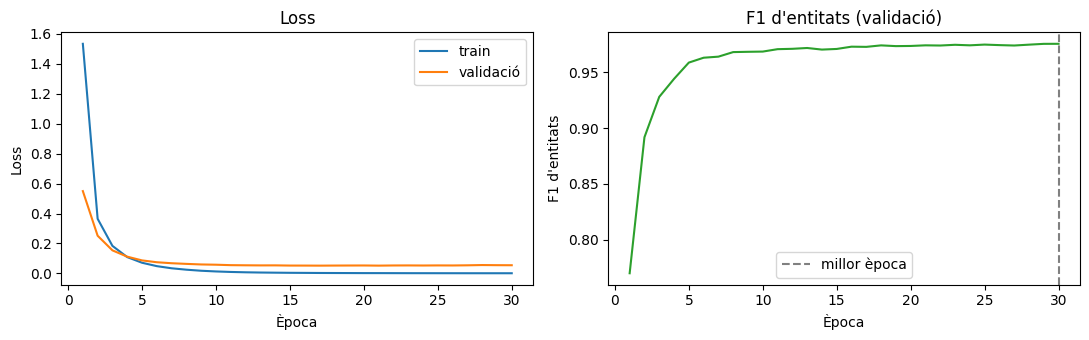

In [26]:
fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(11, 3.5))
epochs_range = range(1, len(history["train_loss"]) + 1)
ax_loss.plot(epochs_range, history["train_loss"], label="train")
ax_loss.plot(epochs_range, history["val_loss"], label="validació")
ax_loss.set(xlabel="Època", ylabel="Loss", title="Loss")
ax_loss.legend()
ax_f1.plot(epochs_range, history["val_f1"], color="tab:green")
ax_f1.axvline(history["best_epoch"], linestyle="--", color="grey", label="millor època")
ax_f1.set(xlabel="Època", ylabel="F1 d'entitats", title="F1 d'entitats (validació)")
ax_f1.legend()
plt.tight_layout()
plt.show()

In [27]:
val_pred = predict(model, val_loader)
test_pred = predict(model, test_loader)

summary = pd.DataFrame({
    name: {"entity_f1": entity_f1(gold, pred), **token_metrics(gold, pred)}
    for name, gold, pred in [("validació", val_gold, val_pred), ("test", test_gold, test_pred)]
}).T
print(summary.round(4), "\n")

print("Test: report a nivell d'entitat (seqeval, mode estricte)")
print(entity_report(test_gold, test_pred, mode="strict", scheme=SEQEVAL_SCHEME, zero_division=0))

           entity_f1  token_acc  token_f1_macro  token_f1_weighted
validació     0.9754     0.9887          0.8197             0.9726
test          0.9528     0.9768          0.7073             0.9437 

Test: report a nivell d'entitat (seqeval, mode estricte)
                            precision    recall  f1-score   support

             aircraft_code       0.93      0.82      0.87        33
              airline_code       0.91      0.85      0.88        34
              airline_name       1.00      0.94      0.97       101
              airport_code       0.36      0.44      0.40         9
              airport_name       0.89      0.38      0.53        21
 arrive_date.date_relative       1.00      1.00      1.00         2
      arrive_date.day_name       0.79      1.00      0.88        11
    arrive_date.day_number       0.67      0.67      0.67         6
    arrive_date.month_name       0.71      0.83      0.77         6
      arrive_time.end_time       0.88      0.88      0.88  

In [28]:
# Report que demana l'enunciat. Només inclou les etiquetes presents al gold de test per no omplir la
# taula de classes amb suport zero.
flat_test_gold = [t for s in test_gold for t in s]
flat_test_pred = [t for s in test_pred for t in s]
print("Test: report token per token")
print(classification_report(flat_test_gold, flat_test_pred, labels=sorted(set(flat_test_gold)), zero_division=0))

Test: report token per token
                              precision    recall  f1-score   support

              B-airline_name       0.95      0.97      0.96        62
              B-airport_name       0.91      0.48      0.62        21
      B-arrive_time.end_time       0.88      0.88      0.88         8
    B-arrive_time.start_time       1.00      1.00      1.00         1
          B-arrive_time.time       0.97      1.00      0.99        34
 B-arrive_time.time_relative       0.00      0.00      0.00         2
                 B-city_name       0.88      0.65      0.75        23
                B-class_type       1.00      1.00      1.00        17
             B-cost_relative       1.00      0.67      0.80         3
    B-depart_date.day_number       1.00      0.93      0.97        15
      B-depart_time.end_time       1.00      0.67      0.80         3
 B-depart_time.period_of_day       1.00      1.00      1.00         1
    B-depart_time.start_time       0.00      0.00      0.00 

**Anàlisi dels resultats.** El baseline arriba a 0,975 de F1 d'entitats a validació i 0,953 a test. La distància
entre la F1 micro (0,95) i la macro (0,73) resumeix el problema principal del dataset: les entitats freqüents
(`fromloc.city_name`, `toloc.city_name`, `depart_date.day_name`) es reconeixen gairebé perfectament, mentre que
moltes de les classes amb pocs exemples tenen F1 baixa o nul·la (`state_name`, `airport_code`, `city_name`). Algunes
són directament impossibles, perquè l'etiqueta no surt mai a train (`booking_class`, `compartment`, `flight`).
L'accuracy per token (0,977) sembla molt alta, però és enganyosa: dos terços dels tokens són `O`. Les corbes mostren
que la loss de validació toca mínim cap a l'època 17 mentre la de train continua baixant fins a 0,001, un senyal
de sobreajust que s'estudia a l'apartat 7.5. Tot i així, la F1 de validació encara puja mil·lèsimes fins a
l'època 30, perquè el model continua ajustant les prediccions d'unes poques entitats.

---

 <h1><a name="ex-seven"><center> ✏ Exercici 7 ✏ </a></h1>

Modifiqueu els següents paràmetres del model anterior i analitzeu com afecten a la seva *accuracy*:

 1. **Mida dels Embeddings.** Proveu diferents mides d'*Embeddings* i observeu com canvia l'*accuracy* del model. Heu d'explicar les vostres conclusions.

 2. **Xarxes Convolucionals.** Afegiu capes convolucionals al vostre model. Expliqueu amb detall els valors que heu provat i la vostra motivació a l'hora d'escollir-los. Recordeu, que també podeu provar diferents configuracions de *pooling*.

 3. **Xarxes Recurrents.**  Afegiu capes recurrents al vostre model (LSTM, GRU). Expliqueu amb detall els valors que heu provat i la vostra motivació.

 4. ** Transformer.** Afegiu blocs de Transformer al vostre model. Expliqueu amb detall els valors que heu provat i la vostra motivació.

 5. **Regularització.** Quan proveu configuracions amb més paràmetres veureu que el model comença a tenir *overfitting* molt prompte durant l'entrenament. Afegiu *Dropout* al vostre model. Heu d'explicar la vostra decisió de valors i de posició dins de la xarxa.


 6. **Balancejat de les classes.** Si analitzeu el dataset, veureu que la freqüència de les classes està molt desbalancejada. Podeu consultar la documentació de la loss per veure com fer-ho (https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

 ---

---

## Exercici 7: metodologia

Tot el codi de l'Exercici 7 és al paquet `parte2/ner/`: configuracions (`config.py`), dades (`data.py`), models
compostos per blocs (`models/`), un únic bucle d'entrenament (`train.py`), mètriques (`metrics.py`) i una
graella per apartat (`experiments/`). Totes les variants comparteixen preprocessament, entrenament i avaluació,
així que les diferències entre resultats només poden venir del factor que es canvia.

El protocol és el mateix a tots els apartats. Es canvia un factor cada vegada respecte al baseline de
l'Exercici 6, cada configuració s'entrena amb 3 llavors i es reporta la mitjana ± la desviació, i totes les
decisions es prenen amb la F1 de validació (el test només s'observa). La mètrica principal és la F1 d'entitats
en mode estricte (seqeval, equivalent a conlleval); també es mostren la F1 macro, que reflecteix les classes
rares, el nombre de paràmetres i el temps per època. El baseline es reentrena amb early stopping més robust
(`min_delta = 0.001` i fins a 40 èpoques), perquè a l'Exercici 6 la F1 encara pujava mil·lèsimes a l'època 30.

Cada execució es desa en un JSON a `parte2/results/` en acabar, de manera que si l'entorn es desconnecta, en
tornar a executar la cel·la només s'entrena el que falta.

In [5]:
# Configuració de l'Exercici 7. Els resultats es desen a parte2/results; si p2/ és a Google Drive, sobreviuen
# a les desconnexions de Colab.
import os
import sys
from pathlib import Path

try:
    from IPython.display import display
except ImportError:
    display = print

# El notebook s'executa des de la carpeta p2/ (a Colab, després de muntar Drive i fer %cd a p2/).
PARTE2_DIR = Path("parte2").resolve()
assert (PARTE2_DIR / "ner").exists(), f"No trobo el paquet ner a {PARTE2_DIR}: el directori actual ha de ser p2/"

os.environ["NER_RESULTS_DIR"] = str(PARTE2_DIR / "results")
sys.path.insert(0, str(PARTE2_DIR))

from ner import run_grid
from ner.experiments import ex7_1, ex7_2, ex7_3, ex7_4, ex7_5, ex7_6, extras, final

# QUICK = True entrena 1 època amb 1 llavor: només serveix per comprovar que tot s'executa.
# El codi de ner/ s'ha de congelar abans de llançar les graelles de debò: la cache identifica cada execució
# per la seva configuració, no per la versió del codi.
QUICK = False
N_WORKERS = 1            # el benchmark de la cel·la següent mostra que a Colab (2 vCPU) paral·lelitzar no compensa
SEEDS = (0,) if QUICK else (0, 1, 2)
FINAL_SEEDS = (0,) if QUICK else final.FINAL_SEEDS


def run(configs, seeds=SEEDS):
    """Llança una graella amb cache; en mode QUICK redueix cada configuració a una sola època."""
    if QUICK:
        configs = [c.with_(**{"train.max_epochs": 1}) for c in configs]
    return run_grid(configs, seeds=seeds, n_workers=N_WORKERS)


def fig_name(name):
    """En mode QUICK no es desen figures, per no sobreescriure les bones amb resultats d'una època."""
    return None if QUICK else name

In [30]:
# Benchmark opcional: quantes execucions simultànies aprofiten millor la GPU. Entrena 4 models curts per a cada
# valor en una carpeta temporal, sense tocar la cache de resultats.
import tempfile
import time

from ner import baseline

if not QUICK:
    results_dir = os.environ["NER_RESULTS_DIR"]
    for workers in (1, 2, 4):
        with tempfile.TemporaryDirectory() as tmp:
            os.environ["NER_RESULTS_DIR"] = tmp
            start = time.perf_counter()
            run_grid([baseline().with_(**{"train.max_epochs": 3})], seeds=(10, 11, 12, 13), n_workers=workers)
            print(f"n_workers = {workers}: {time.perf_counter() - start:.0f} s")
    os.environ["NER_RESULTS_DIR"] = results_dir

4 execucions, 0 ja a la cache, 4 per entrenar
[1/4] baseline (seed 10): val F1 0.9357, 3 èpoques, 0.1 min
[2/4] baseline (seed 11): val F1 0.9243, 3 èpoques, 0.2 min
[3/4] baseline (seed 12): val F1 0.9283, 3 èpoques, 0.3 min
[4/4] baseline (seed 13): val F1 0.9304, 3 èpoques, 0.4 min
n_workers = 1: 22 s
4 execucions, 0 ja a la cache, 4 per entrenar
[1/4] baseline (seed 10): val F1 0.9357, 3 èpoques, 0.3 min
[2/4] baseline (seed 11): val F1 0.9243, 3 èpoques, 0.3 min
[3/4] baseline (seed 12): val F1 0.9283, 3 èpoques, 0.5 min
[4/4] baseline (seed 13): val F1 0.9304, 3 èpoques, 0.5 min
n_workers = 2: 31 s
4 execucions, 0 ja a la cache, 4 per entrenar
[1/4] baseline (seed 12): val F1 0.9283, 3 èpoques, 0.6 min
[2/4] baseline (seed 11): val F1 0.9243, 3 èpoques, 0.6 min
[3/4] baseline (seed 10): val F1 0.9357, 3 èpoques, 0.6 min
[4/4] baseline (seed 13): val F1 0.9304, 3 èpoques, 0.6 min
n_workers = 4: 39 s


### 7.1 Mida dels embeddings i embeddings preentrenats

Es proven embeddings aleatoris de 16 a 512 dimensions i GloVe (50, 100, 200 i 300) congelat i amb fine-tuning.
Hipòtesi: amb un vocabulari d'unes 600 paraules la F1 hauria de saturar cap a 50-100 dimensions i empitjorar
lleugerament per sobre de 256 per sobreajust. GloVe hauria d'ajudar sobretot amb paraules rares o no vistes
(Jurafsky & Martin, cap. 6). Com que el vocabulari amb GloVe també inclou les paraules que surten un sol cop a
train, el control `aleatori-100 min_freq=1` separa l'efecte del vocabulari del dels vectors preentrenats.

Cobertura de GloVe sobre el vocabulari del baseline: 99.5%


,vocab,unk_val,unk_test
baseline (min_freq=2),589,0.0111,0.0144
min_freq=1,832,0.0068,0.0083
GloVe,929,0.0005,0.0010


57 execucions, 57 ja a la cache, 0 per entrenar


,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds
name,,,,,,,,,,,,
aleatori-16,0.9597,0.0051,0.9300,0.0035,0.6861,0.0118,0.6698,0.0172,204931.0,25.0000,1.8770,3
aleatori-32,0.9646,0.0010,0.9399,0.0017,0.7037,0.0173,0.6785,0.0160,230739.0,23.0000,1.8697,3
aleatori-50,0.9684,0.0026,0.9438,0.0032,0.7077,0.0220,0.6931,0.0178,259773.0,21.6667,1.8650,3
aleatori-64,0.9687,0.0010,0.9425,0.0012,0.7213,0.0167,0.6954,0.0074,282355.0,17.3333,1.8722,3
aleatori-100,0.9749,0.0009,0.9475,0.0029,0.7278,0.0155,0.7147,0.0148,340423.0,17.3333,1.8544,3
aleatori-128,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,385587.0,12.6667,1.8963,3
aleatori-200,0.9759,0.0012,0.9470,0.0017,0.7280,0.0120,0.7079,0.0160,501723.0,14.6667,1.8628,3
aleatori-256,0.9748,0.0013,0.9458,0.0007,0.7260,0.0064,0.6995,0.0106,592051.0,12.0000,1.8796,3
aleatori-300,0.9744,0.0005,0.9467,0.0006,0.7086,0.0137,0.6902,0.0092,663023.0,12.6667,1.8902,3


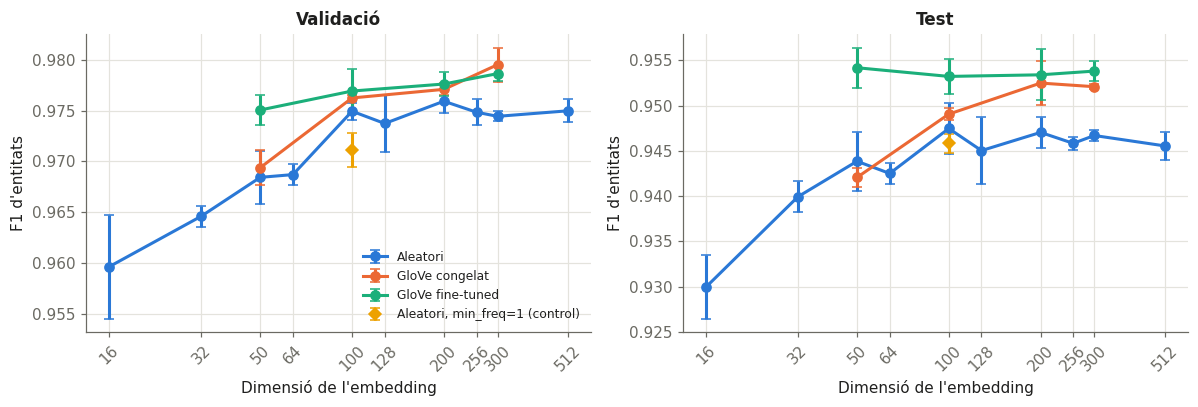

In [6]:
display(ex7_1.vocab_stats().round(4))
r71 = run(ex7_1.configs())
s71, fig71 = ex7_1.report(r71, save_as=fig_name("ex7_1_embeddings"))
display(s71.round(4))

**Anàlisi dels resultats.** La mida de l'embedding importa fins a unes 100 dimensions. De 16 a 100 la F1 de
validació puja de 0,960 a 0,975, i a partir d'aquí queda plana (entre 0,974 i 0,976 fins a 512), dins de la
variabilitat entre llavors. No apareix l'empitjorament per sobreajust que esperàvem per sobre de 256. El que sí
canvia és la velocitat: la millor època passa de 25 (16 dimensions) a 10 (512), és a dir, els embeddings grans
aprenen més de pressa i l'early stopping els atura abans que la capacitat extra arribi a fer mal. La F1 macro sí
que baixa una mica a 300-512 (0,70-0,71 enfront de 0,73 a 100-200), un primer senyal que les classes rares en
surten perjudicades.

GloVe és el canvi més clar de l'apartat. Amb 300 dimensions i congelat arriba a 0,9795 de validació (+0,5 punts
sobre el millor aleatori), i a test tots els GloVe de 100 o més dimensions superen tots els embeddings aleatoris
(0,949-0,954 enfront de 0,930-0,948). On més es nota és a la F1 macro: 0,74-0,77 enfront de 0,69-0,73, uns 4-5
punts, i això confirma que el guany ve de les paraules rares. El control descarta que sigui un efecte del
vocabulari més gran: amb `min_freq = 1` i vectors aleatoris la F1 no millora (0,9711, per sota de l'aleatori de 100
dimensions). Entre congelat i fine-tuned no hi ha una diferència consistent: el fine-tuning va una mica millor a
test amb poques dimensions i el congelat amb 300. Congelar té l'avantatge de no haver d'entrenar els ~280.000
paràmetres dels vectors, i amb 300 dimensions els vectors originals ja són prou expressius.

### 7.2 Xarxes convolucionals i pooling

Tres usos de la convolució: una CNN de paraula davant de la BiLSTM, una CNN sola i una char-CNN amb max-pooling
sobre els caràcters de cada paraula (Ma & Hovy, 2016). Un global pooling sol no serveix en NER perquè elimina la
sortida per token; aquí el pooling es fa servir com a max-pooling local amb stride 1, com a vector de context
global concatenat a cada token i dins de la char-CNN. Hipòtesi: la CNN davant de la BiLSTM aporta poc perquè la
BiLSTM ja captura el context local; la CNN sola falla en etiquetes que depenen de paraules llunyanes
(`arrive_time` vs `depart_time`); la char-CNN millora les paraules fora de vocabulari.

54 execucions, 3 ja a la cache, 51 per entrenar
[1/51] CNN k3 → BiLSTM (seed 0): val F1 0.9751, 16 èpoques, 1.0 min
[2/51] CNN k3 → BiLSTM (seed 1): val F1 0.9747, 23 èpoques, 1.2 min
[3/51] CNN k3 → BiLSTM (seed 2): val F1 0.9763, 19 èpoques, 1.7 min
[4/51] CNN k5 → BiLSTM (seed 0): val F1 0.9732, 21 èpoques, 2.1 min
[5/51] CNN k5 → BiLSTM (seed 1): val F1 0.9688, 16 èpoques, 2.4 min
[6/51] CNN k5 → BiLSTM (seed 2): val F1 0.9737, 26 èpoques, 3.2 min
[7/51] CNN k7 → BiLSTM (seed 0): val F1 0.9681, 21 èpoques, 3.3 min
[8/51] CNN k7 → BiLSTM (seed 2): val F1 0.9672, 15 èpoques, 3.9 min
[9/51] CNN k7 → BiLSTM (seed 1): val F1 0.9640, 17 èpoques, 3.9 min
[10/51] CNN k3+5 → BiLSTM (seed 0): val F1 0.9730, 19 èpoques, 4.8 min
[11/51] CNN k3+5 → BiLSTM (seed 1): val F1 0.9703, 20 èpoques, 4.8 min
[12/51] CNN k3 f64 → BiLSTM (seed 0): val F1 0.9747, 17 èpoques, 5.6 min
[13/51] CNN k3+5 → BiLSTM (seed 2): val F1 0.9727, 20 èpoques, 5.6 min
[14/51] CNN k3 f64 → BiLSTM (seed 2): val F1 0.9722, 1

,family,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds,oov_token_acc
name,,,,,,,,,,,,,,
baseline (BiLSTM),Referència,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,385587.0,12.6667,1.8963,3,0.5526
CNN k3 → BiLSTM,CNN → BiLSTM,0.9754,0.0008,0.9447,0.0038,0.7117,0.0163,0.7090,0.0096,434867.0,14.3333,2.0822,3,0.5833
CNN k5 → BiLSTM,CNN → BiLSTM,0.9719,0.0027,0.9431,0.0022,0.7093,0.0167,0.6968,0.0139,467635.0,16.0000,2.0467,3,0.5702
CNN k7 → BiLSTM,CNN → BiLSTM,0.9664,0.0022,0.9371,0.0015,0.6979,0.0171,0.6869,0.0054,500403.0,12.6667,2.0326,3,0.5833
CNN k3+5 → BiLSTM,CNN → BiLSTM,0.9720,0.0015,0.9448,0.0011,0.7188,0.0184,0.7066,0.0137,451251.0,14.6667,2.2631,3,0.5614
CNN k3 f64 → BiLSTM,CNN → BiLSTM,0.9742,0.0018,0.9428,0.0001,0.7091,0.0207,0.6984,0.0148,344691.0,15.3333,2.0461,3,0.5877
CNN k3 f256 → BiLSTM,CNN → BiLSTM,0.9744,0.0017,0.9453,0.0020,0.7185,0.0102,0.7085,0.0021,615219.0,12.3333,1.9760,3,0.5746
CNN k3 ×2 → BiLSTM,CNN → BiLSTM,0.9673,0.0036,0.9382,0.0050,0.6652,0.0142,0.6619,0.0264,484147.0,16.3333,2.1381,3,0.5482
CNN k3 ×1,Només CNN,0.9217,0.0020,0.8925,0.0020,0.5418,0.0104,0.5320,0.0043,147763.0,9.6667,0.5751,3,0.5526


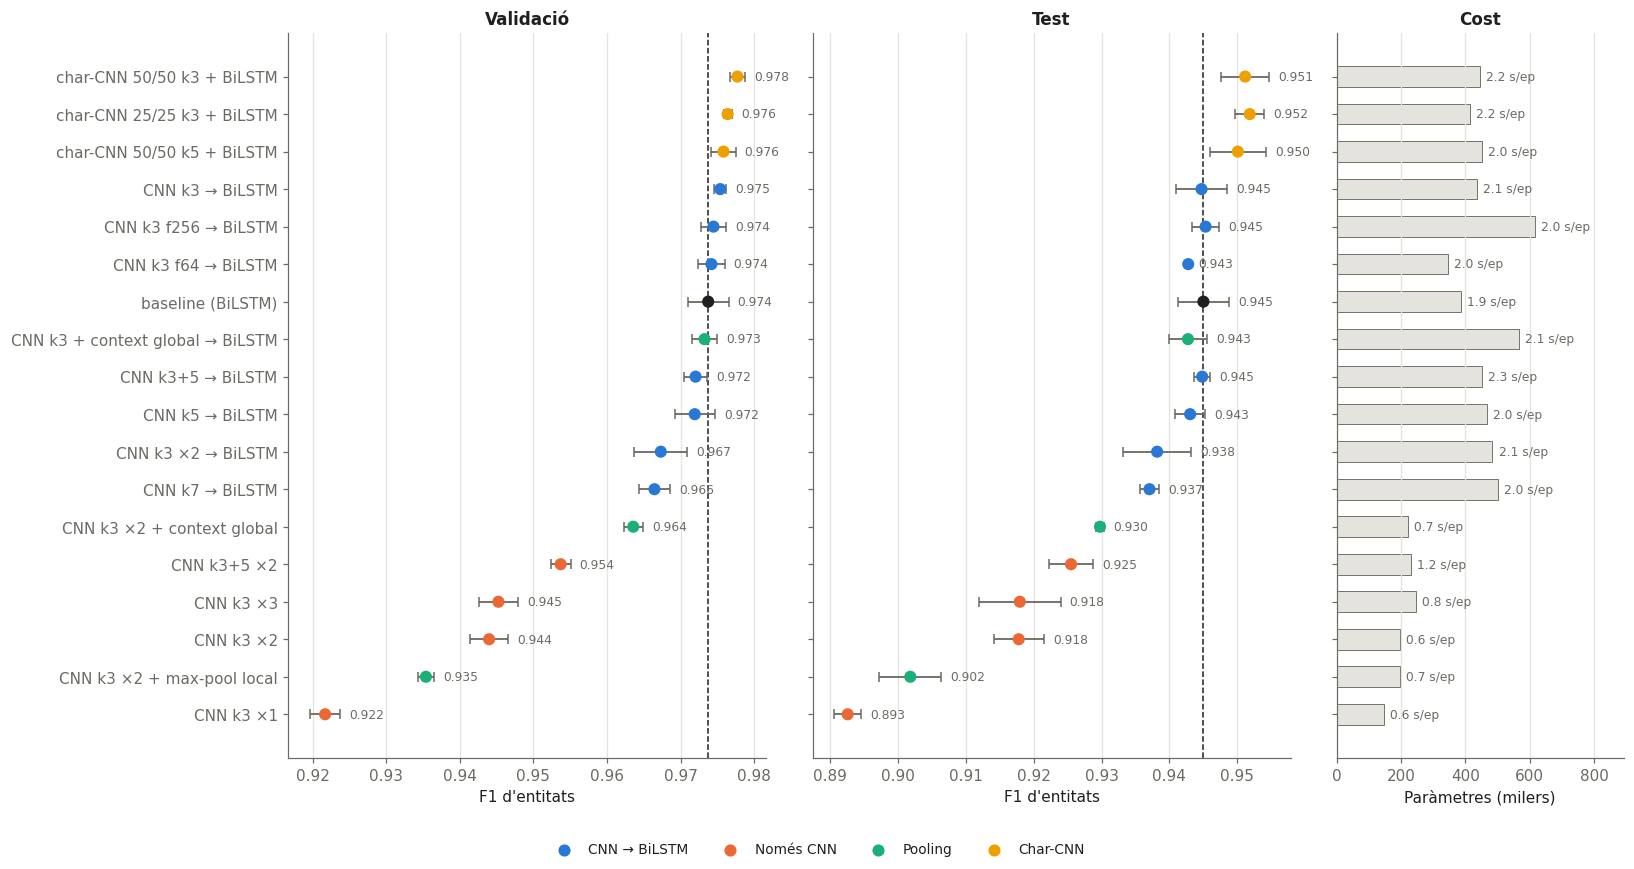

In [9]:
r72 = run(ex7_2.configs())
s72, fig72 = ex7_2.report(r72, save_as=fig_name("ex7_2_cnn"))
display(s72.round(4))

**Anàlisi dels resultats.** Davant de la BiLSTM, la CNN de paraula no aporta res: la millor variant (kernel 3,
0,9754) queda dins del soroll del baseline (0,9737 ± 0,0028), i a test totes queden entre 0,937 i 0,945. Els
kernels grans i les dues capes empitjoren (0,966-0,967), tal com esperàvem: la BiLSTM ja veu el context local, i
la CNN només hi afegeix paràmetres i un pas més on es pot difuminar la informació de cada paraula.

Sense recurrència, la CNN queda clarament per sota (0,922-0,954 de validació, 0,89-0,93 de test) i millora amb el
camp receptiu, de 3 paraules (0,922) a 5 (0,944) i a la combinació de kernels 3+5 (0,954). És la confirmació que
moltes etiquetes depenen de context llunyà. El pooling es comporta com preveia la hipòtesi. El max-pooling local
empitjora (0,935 enfront de 0,944), perquè barreja activacions de paraules veïnes i difumina els límits de les
entitats. El vector de context global és el que més ajuda a la CNN sola (+2 punts de validació i +5 de F1 macro),
perquè li dona informació de tota l'oració que el seu camp receptiu no arriba a veure; sobre la BiLSTM, en canvi,
és redundant (0,9732).

La char-CNN és l'única variant que millora el baseline: 0,9777 de validació (50/50, kernel 3), 0,951-0,952 de
test i 3-4 punts més de F1 macro. L'accuracy sobre els 76 tokens de test amb paraula no vista puja de 0,55 a
0,57-0,60, una millora en la direcció esperada però petita en termes absoluts (entre 1 i 4 tokens). Per tant, el
guany de la char-CNN no ve només de les paraules desconegudes, sinó també de representar millor paraules rares
conegudes com números de vol o codis d'aeroport. El cost és petit, un 16% més de temps per època. A l'altre
extrem, la CNN sola és unes tres vegades més ràpida que la BiLSTM (0,6-0,75 s per època enfront de 1,9 s), una
opció raonable si la latència importés més que l'últim punt de F1.

### 7.3 Xarxes recurrents

Primer es canvia un factor cada vegada (tipus de cel·la, direcció, capes i mida de l'estat) i després es creuen
automàticament els guanyadors de cada factor amb el valor del baseline. La LSTM unidireccional de 256 unitats té
la mateixa mida de sortida que la BiLSTM de 128 i separa l'efecte de la direcció del de la capacitat. Hipòtesi:
LSTM i GRU queden a prop (oracions curtes), la bidireccionalitat és el factor més important i més capes sense
dropout sobreajusten.

24 execucions, 3 ja a la cache, 21 per entrenar
[1/21] BiGRU 1×128 (seed 0): val F1 0.9732, 23 èpoques, 1.0 min
[2/21] BiGRU 1×128 (seed 1): val F1 0.9751, 25 èpoques, 1.1 min
[3/21] BiGRU 1×128 (seed 2): val F1 0.9725, 16 èpoques, 1.6 min
[4/21] LSTM 1×128 (seed 0): val F1 0.9489, 25 èpoques, 1.9 min
[5/21] LSTM 1×128 (seed 1): val F1 0.9463, 18 èpoques, 2.2 min
[6/21] LSTM 1×256 (seed 0): val F1 0.9468, 15 èpoques, 2.7 min
[7/21] LSTM 1×128 (seed 2): val F1 0.9472, 27 èpoques, 2.7 min
[8/21] LSTM 1×256 (seed 2): val F1 0.9450, 15 èpoques, 3.2 min
[9/21] LSTM 1×256 (seed 1): val F1 0.9495, 19 èpoques, 3.3 min
[10/21] BiLSTM 2×128 (seed 0): val F1 0.9738, 16 èpoques, 4.1 min
[11/21] BiLSTM 2×128 (seed 1): val F1 0.9751, 17 èpoques, 4.2 min
[12/21] BiLSTM 2×128 (seed 2): val F1 0.9725, 17 èpoques, 4.9 min
[13/21] BiLSTM 3×128 (seed 0): val F1 0.9711, 21 èpoques, 5.5 min
[14/21] BiLSTM 3×128 (seed 1): val F1 0.9736, 18 èpoques, 6.1 min
[15/21] BiLSTM 3×128 (seed 2): val F1 0.9715, 18 èpo

,family,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds
name,,,,,,,,,,,,,
BiLSTM 1×128 (baseline),Referència,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,385587.0,12.6667,1.8963,3
BiGRU 1×128,Tipus de cel·la,0.9736,0.0013,0.9494,0.0015,0.7239,0.0046,0.7018,0.0112,319539.0,16.3333,1.8482,3
LSTM 1×128,Direcció,0.9475,0.0013,0.9200,0.0032,0.6686,0.0393,0.6143,0.0351,230579.0,18.3333,1.5195,3
LSTM 1×256,Direcció,0.9471,0.0023,0.9229,0.0023,0.6970,0.0139,0.6292,0.0086,516659.0,11.3333,1.5434,3
BiLSTM 2×128,Capes,0.9738,0.0013,0.9493,0.0037,0.7417,0.0263,0.7247,0.0109,780851.0,11.6667,2.5357,3
BiLSTM 3×128,Capes,0.9721,0.0013,0.9428,0.0030,0.7097,0.0332,0.7037,0.0270,1176115.0,14.0000,3.2712,3
BiLSTM 1×64,Mida de l'estat,0.9747,0.0009,0.9453,0.0011,0.6847,0.0092,0.6747,0.0147,197811.0,21.3333,1.8713,3
BiLSTM 1×256,Mida de l'estat,0.9748,0.0009,0.9494,0.0028,0.7383,0.0023,0.7132,0.0095,957747.0,12.6667,1.9279,3
BiLSTM 2×256,Creuament,0.9765,0.0003,0.9508,0.0023,0.7462,0.0067,0.7229,0.0058,2534707.0,12.3333,2.3823,3


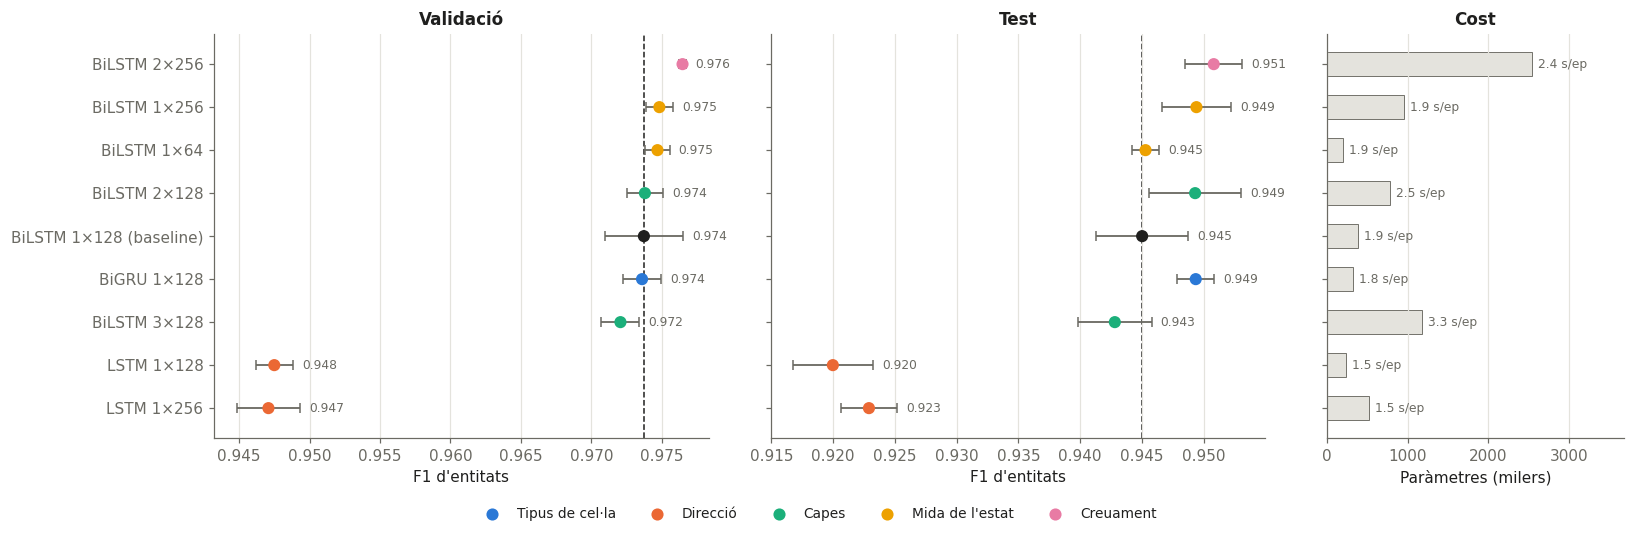

In [10]:
r73 = run(ex7_3.configs())
r73 += run(ex7_3.cross_configs(r73))
s73, fig73 = ex7_3.report(r73, save_as=fig_name("ex7_3_rnn"))
display(s73.round(4))

**Anàlisi dels resultats.** La bidireccionalitat és, de lluny, el factor més important. Sense context dret la F1
cau 2,6 punts a validació i 2,5 a test, i la LSTM unidireccional de 256 unitats, que té la mateixa mida de
sortida que la BiLSTM de 128 i un 34% més de paràmetres, no recupera res (0,9471). La pèrdua és, per tant, de
context i no de capacitat. LSTM i GRU queden empatades a validació (0,9737 i 0,9736); la GRU va 0,4 punts millor a
test amb un 17% menys de paràmetres, però amb 3 llavors aquesta diferència està al límit del soroll. La
profunditat i la mida de l'estat gairebé no importen: 2 capes empaten, 3 empitjoren lleugerament (0,9721) i
qualsevol mida entre 64 i 256 dona el mateix resultat.

El creuament dels guanyadors (BiLSTM 2×256) és la millor configuració (0,9765), però el guany (+0,28 punts) és igual
a la desviació del baseline i costa 6,5 vegades més paràmetres, i per això no entra al model final. Amb oracions
curtes i 4k exemples, la BiLSTM d'una capa ja està saturada: el que limita el rendiment és la informació
d'entrada, no la mida de l'encoder.

### 7.4 Transformer

Un encoder Transformer sol (amb posició sinusoidal, apresa o sense posició) i un híbrid amb capes d'atenció
sobre la BiLSTM. La primera fase compara la recepta d'optimització del baseline amb LR 5e-4 i warmup; la segona
fa servir la recepta guanyadora a totes les variants. Hipòtesi: entrenat des de zero amb 4k oracions, el
Transformer sol queda per sota de la BiLSTM perquè no té biaix de seqüencialitat; sense posició falla en
distincions d'ordre com `fromloc`/`toloc`; l'híbrid iguala o millora lleugerament el baseline.

9 execucions, 3 ja a la cache, 6 per entrenar
[1/6] Transformer ref. (recepta baseline) (seed 1): val F1 0.9459, 14 èpoques, 0.6 min
[2/6] Transformer ref. (recepta baseline) (seed 0): val F1 0.9477, 20 èpoques, 0.8 min
[3/6] Transformer ref. (recepta baseline) (seed 2): val F1 0.9509, 17 èpoques, 1.2 min
[4/6] Transformer ref. (LR 5e-4 + warmup) (seed 0): val F1 0.9458, 26 èpoques, 1.6 min
[5/6] Transformer ref. (LR 5e-4 + warmup) (seed 1): val F1 0.9440, 18 èpoques, 1.8 min
[6/6] Transformer ref. (LR 5e-4 + warmup) (seed 2): val F1 0.9430, 21 èpoques, 2.1 min
Recepta guanyadora per validació: recepta baseline
27 execucions, 0 ja a la cache, 27 per entrenar
[1/27] Transformer 1 capa (seed 0): val F1 0.9461, 15 èpoques, 0.5 min
[2/27] Transformer 1 capa (seed 1): val F1 0.9363, 21 èpoques, 0.6 min
[3/27] Transformer 1 capa (seed 2): val F1 0.9457, 15 èpoques, 0.9 min
[4/27] Transformer 4 capes (seed 0): val F1 0.9518, 19 èpoques, 1.6 min
[5/27] Transformer 4 capes (seed 1): val F1 0.95

,family,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds
name,,,,,,,,,,,,,
BiLSTM (baseline),Referència,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,385587.0,12.6667,1.8963,3
Transformer ref. (recepta baseline),Recepta,0.9481,0.0025,0.9148,0.0035,0.6133,0.0134,0.5897,0.0255,363699.0,12.0000,1.5950,3
Transformer ref. (LR 5e-4 + warmup),Recepta,0.9443,0.0015,0.9097,0.0021,0.6207,0.0246,0.5898,0.0321,363699.0,16.6667,1.3965,3
Transformer 1 capa,Profunditat,0.9427,0.0055,0.9068,0.0048,0.6048,0.0051,0.5844,0.0042,231219.0,12.0000,1.0593,3
Transformer 4 capes,Profunditat,0.9555,0.0037,0.9202,0.0040,0.6420,0.0199,0.6103,0.0246,628659.0,16.3333,2.7131,3
Transformer 2 caps,Caps d'atenció,0.9472,0.0066,0.9122,0.0061,0.6251,0.0284,0.5935,0.0265,363699.0,18.0000,1.6037,3
Transformer 8 caps,Caps d'atenció,0.9497,0.0059,0.9107,0.0033,0.6046,0.0149,0.5704,0.0094,363699.0,16.3333,1.5946,3
Transformer FF 512,Feed-forward,0.9477,0.0055,0.9098,0.0117,0.6210,0.0273,0.5863,0.0188,495283.0,13.6667,1.6054,3
Transformer pos. apresa,Posició,0.9406,0.0034,0.9123,0.0025,0.6045,0.0128,0.5664,0.0210,380083.0,10.3333,1.6490,3


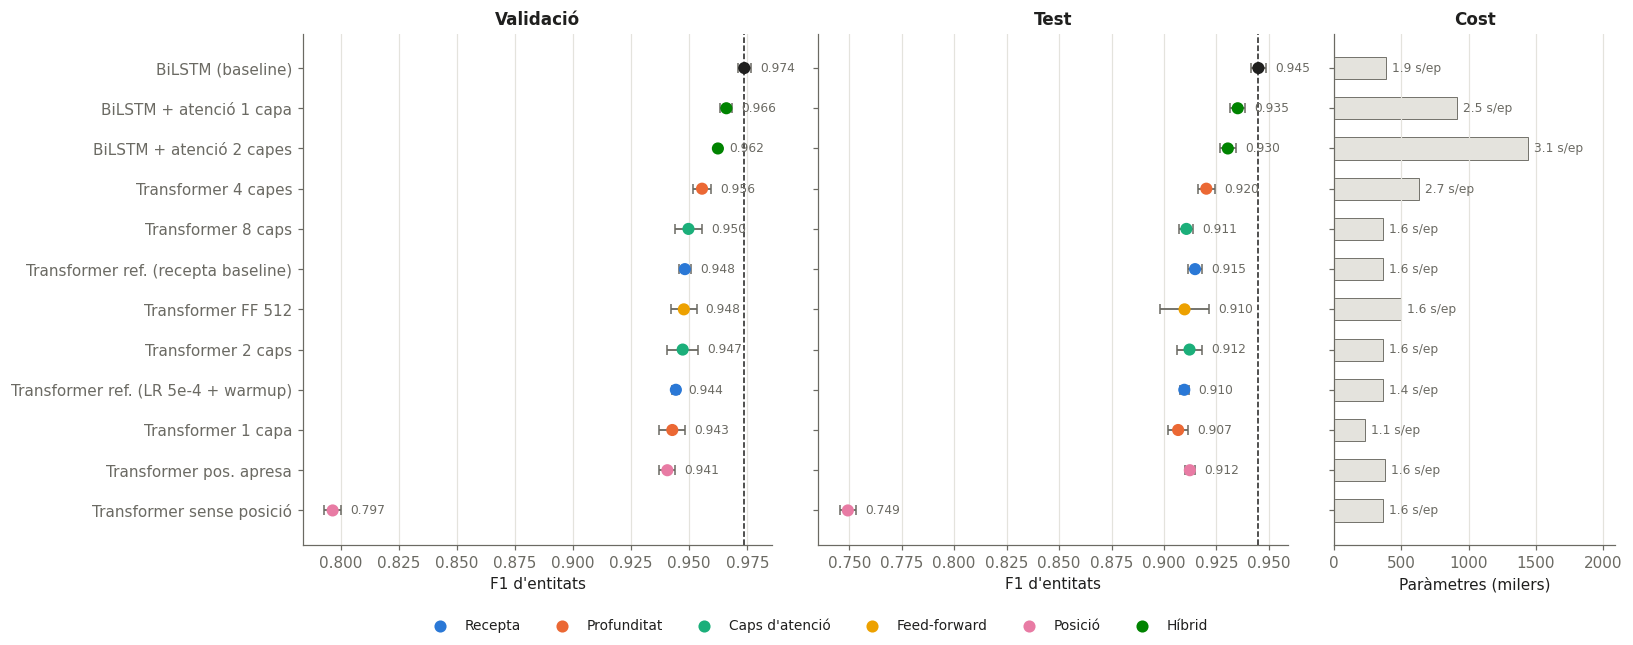

In [11]:
r74 = run(ex7_4.configs())
r74 += run(ex7_4.variant_configs(r74))
s74, fig74 = ex7_4.report(r74, save_as=fig_name("ex7_4_transformer"))
display(s74.round(4))

**Anàlisi dels resultats.** El Transformer sol queda clarament per sota de la BiLSTM, com esperàvem: 0,948 de
validació i 0,915 de test amb la configuració de referència (−3 punts a test) i, sobretot, 10 punts menys de F1
macro (0,61 enfront de 0,72). Les classes rares són les que més pateixen la manca de biaix inductiu: el model ha
d'aprendre de les dades tant el significat com l'ordre, i una etiqueta amb pocs exemples no en dona prou. El
control sense posició ho fa evident: la F1 cau a 0,797, perquè sense ordre el model no pot distingir "from boston
to denver" de "from denver to boston". La posició sinusoidal va lleugerament millor que l'apresa (0,948 enfront
de 0,941), coherent amb el fet que l'apresa s'ha d'aprendre amb poques dades. La recepta amb LR menor i warmup no
ajuda (0,944), així que la comparació amb el baseline no queda afectada per l'optimitzador.

Hi ha dues sorpreses respecte a les hipòtesis. La primera és que més capes ajuden en lloc de sobreajustar: amb 4
capes el Transformer arriba a 0,9555, el millor de la família, probablement perquè cada capa amplia la barreja
d'informació entre posicions i compensa l'absència de recurrència. La segona és que l'híbrid BiLSTM + atenció
no iguala el baseline (0,966 i 0,962). La distància entre la loss de train i la de validació és la més gran de
tot l'exercici (0,077) i, amb dues capes, la millor època és la 7: les capes d'atenció sense dropout memoritzen
el conjunt d'entrenament. L'apartat 7.5 ho confirma, ja que amb dropout 0,3 l'híbrid puja a 0,9735 de validació
i 0,948 de test, al nivell del baseline.

### 7.5 Regularització amb dropout

Dropout sobre l'embedding, entre capes recurrents, abans del classificador i dins del Transformer, en tres
models: el baseline, una BiLSTM 2×256 i el millor model amb atenció de l'apartat anterior. Cada posició es prova
sola (p = 0.3) i després totes juntes (p = 0.1, 0.3, 0.5). Hipòtesi: l'efecte més clar és al model gran (menys
distància entre la loss de train i la de validació i millor F1); p = 0.5 és massa per a un dataset tan petit.

Model d'atenció escollit de l'apartat 7.4: BiLSTM + atenció 1 capa
57 execucions, 9 ja a la cache, 48 per entrenar
[1/48] BiLSTM 1×128 + embedding 0.3 (seed 0): val F1 0.9726, 20 èpoques, 0.9 min
[2/48] BiLSTM 1×128 + embedding 0.3 (seed 1): val F1 0.9759, 25 èpoques, 1.1 min
[3/48] BiLSTM 1×128 + classificador 0.3 (seed 0): val F1 0.9740, 21 èpoques, 1.9 min
[4/48] BiLSTM 1×128 + embedding 0.3 (seed 2): val F1 0.9750, 26 èpoques, 1.9 min
[5/48] BiLSTM 1×128 + classificador 0.3 (seed 2): val F1 0.9728, 16 èpoques, 2.5 min
[6/48] BiLSTM 1×128 + classificador 0.3 (seed 1): val F1 0.9783, 24 èpoques, 2.8 min
[7/48] BiLSTM 1×128 + tot 0.1 (seed 0): val F1 0.9698, 15 èpoques, 3.2 min
[8/48] BiLSTM 1×128 + tot 0.1 (seed 2): val F1 0.9716, 15 èpoques, 3.8 min
[9/48] BiLSTM 1×128 + tot 0.1 (seed 1): val F1 0.9773, 24 èpoques, 3.8 min
[10/48] BiLSTM 1×128 + tot 0.3 (seed 1): val F1 0.9774, 29 èpoques, 4.9 min
[11/48] BiLSTM 1×128 + tot 0.3 (seed 0): val F1 0.9773, 30 èpoques, 4.9 min
[12/48] Bi

,model,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds,loss_gap
name,,,,,,,,,,,,,,
BiLSTM 1×128 sense dropout,BiLSTM 1×128,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,385587.0,12.6667,1.8963,3,0.0474
BiLSTM 1×128 + embedding 0.3,BiLSTM 1×128,0.9745,0.0017,0.9504,0.0012,0.7471,0.0200,0.7227,0.0190,385587.0,18.6667,1.8854,3,0.0371
BiLSTM 1×128 + classificador 0.3,BiLSTM 1×128,0.9751,0.0029,0.9452,0.0018,0.7191,0.0395,0.6908,0.0284,385587.0,15.3333,1.8837,3,0.0435
BiLSTM 1×128 + tot 0.1,BiLSTM 1×128,0.9729,0.0039,0.9464,0.0007,0.7169,0.0187,0.6903,0.0123,385587.0,13.0000,1.9237,3,0.0382
BiLSTM 1×128 + tot 0.3,BiLSTM 1×128,0.9769,0.0007,0.9506,0.0026,0.7460,0.0394,0.7249,0.0219,385587.0,23.0000,1.9393,3,0.0370
BiLSTM 1×128 + tot 0.5,BiLSTM 1×128,0.9732,0.0019,0.9499,0.0029,0.7504,0.0263,0.7144,0.0345,385587.0,22.6667,1.9718,3,0.0064
BiLSTM 2×256 sense dropout,BiLSTM 2×256,0.9765,0.0003,0.9508,0.0023,0.7462,0.0067,0.7229,0.0058,2534707.0,12.3333,2.3823,3,0.0550
BiLSTM 2×256 + embedding 0.3,BiLSTM 2×256,0.9766,0.0015,0.9503,0.0030,0.7463,0.0176,0.7263,0.0155,2534707.0,12.0000,2.7350,3,0.0456
BiLSTM 2×256 + entre capes 0.3,BiLSTM 2×256,0.9763,0.0009,0.9512,0.0027,0.7481,0.0088,0.7199,0.0177,2534707.0,10.0000,2.7210,3,0.0503


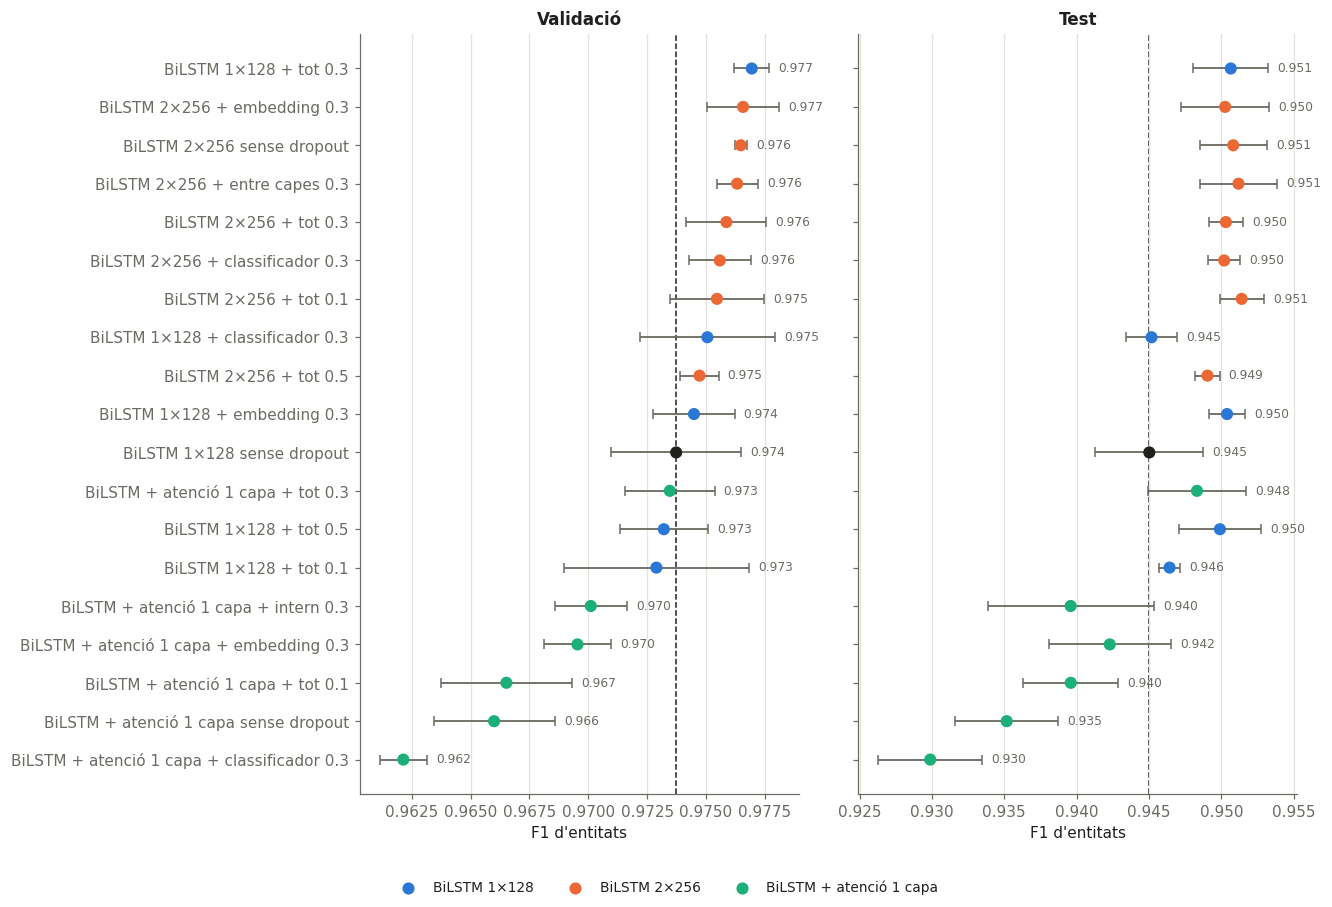

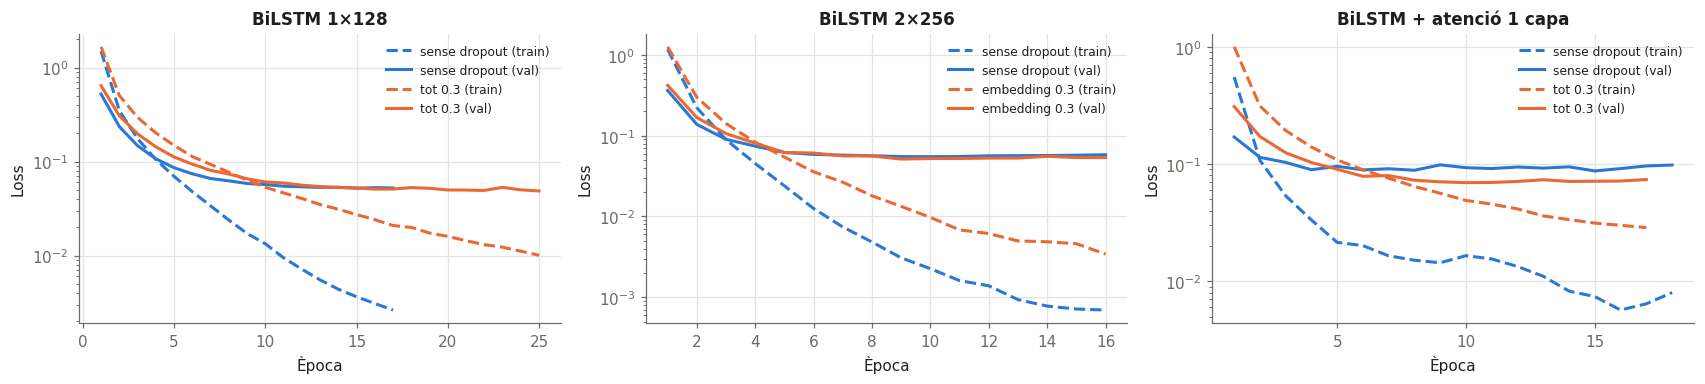

In [12]:
r75 = run(ex7_5.configs(r74))
s75, fig75, curves75 = ex7_5.report(r75, save_as=fig_name("ex7_5_dropout"))
display(s75.round(4))

**Anàlisi dels resultats.** L'efecte del dropout depèn molt del model. Al baseline, el dropout de 0,3 a
l'embedding i abans del classificador millora 0,3 punts de validació, 0,6 de test i 3 de F1 macro, i el model
entrena més èpoques abans d'aturar-se (23 enfront de 13). La posició que més aporta és l'embedding, que sola ja
dona gairebé tota la millora de test (0,9504) i de F1 macro (0,747), com esperàvem per la gran proporció de
paraules rares; el dropout abans del classificador, sol, no canvia res. Amb p = 0,5 la distància entre la loss de
train i la de validació gairebé desapareix (0,006 enfront de 0,047), però la F1 de validació torna a baixar
(0,9732), un indici que el model comença a infraajustar.

On el dropout és imprescindible és al model amb atenció: passa de 0,966 a 0,9735 de validació i de 0,935 a 0,948
de test, la distància de loss es redueix a la meitat (0,077 → 0,040) i la F1 macro puja de 0,67 a 0,76. En canvi,
i contra la nostra hipòtesi, la BiLSTM 2×256 no en treu cap profit: totes les variants queden dins del soroll
(0,9747-0,9766). La distància de loss sí que es redueix (0,055 → 0,025 amb p = 0,5), però la F1 no es mou. La
interpretació és que l'early stopping ja és un regularitzador suficient per a una BiLSTM: el sobreajust es veu a
la loss, però l'entrenament s'atura abans que afecti les prediccions. Les capes d'atenció, que sobreajusten molt
més de pressa, no tenen aquest marge.

### 7.6 Balanceig de les classes

Pesos a la cross-entropy segons la freqüència de cada etiqueta a train: inversa (amb i sense límit), inversa de
l'arrel, nombre efectiu de mostres (Cui et al., 2019) i reduir només el pes de `O`. Hipòtesi: els pesos pugen el
recall i la F1 de les classes rares a canvi de precisió; la inversa pura és massa agressiva i el límit o l'arrel
donen el millor compromís.

,pes O,mínim,mediana,màxim
sense pesos,1.000,1.000,1.000,1.000
inversa,0.009,0.009,20.067,260.871
"inversa, límit 10",0.009,0.009,10.000,10.000
inversa de l'arrel,0.214,0.214,10.226,36.872
"inversa de l'arrel, límit 10",0.214,0.214,10.000,10.000
nombre efectiu (β=0.999),0.215,0.215,16.600,214.508
només O × 0.5,0.500,0.500,1.000,1.000
només O × 0.25,0.250,0.250,1.000,1.000


24 execucions, 3 ja a la cache, 21 per entrenar
[1/21] inversa (seed 1): val F1 0.9695, 40 èpoques, 1.7 min
[2/21] inversa (seed 0): val F1 0.9673, 40 èpoques, 1.7 min
[3/21] inversa, límit 10 (seed 0): val F1 0.9710, 39 èpoques, 3.2 min
[4/21] inversa (seed 2): val F1 0.9699, 40 èpoques, 3.2 min
[5/21] inversa, límit 10 (seed 2): val F1 0.9693, 36 èpoques, 4.5 min
[6/21] inversa, límit 10 (seed 1): val F1 0.9695, 39 èpoques, 4.7 min
[7/21] inversa de l'arrel (seed 1): val F1 0.9721, 17 èpoques, 5.4 min
[8/21] inversa de l'arrel (seed 0): val F1 0.9708, 21 èpoques, 5.4 min
[9/21] inversa de l'arrel, límit 10 (seed 0): val F1 0.9718, 24 èpoques, 6.3 min
[10/21] inversa de l'arrel (seed 2): val F1 0.9741, 25 èpoques, 6.3 min
[11/21] inversa de l'arrel, límit 10 (seed 1): val F1 0.9719, 19 èpoques, 7.0 min
[12/21] inversa de l'arrel, límit 10 (seed 2): val F1 0.9723, 19 èpoques, 7.1 min
[13/21] nombre efectiu (β=0.999) (seed 0): val F1 0.9719, 25 èpoques, 8.0 min
[14/21] nombre efectiu (β

,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,test_entity_p_mean,test_entity_p_std,...,test_f1_rare_mean,test_f1_rare_std,test_f1_mid_mean,test_f1_mid_std,test_f1_frequent_mean,test_f1_frequent_std,n_params,best_epoch,sec_per_epoch,n_seeds
name,,,,,,,,,,,,,,,,,,,,,
sense pesos,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,0.9541,0.0033,...,0.3128,0.0451,0.7758,0.0178,0.9542,0.0055,385587.0,12.6667,1.8963,3
inversa,0.9689,0.0014,0.9395,0.0015,0.6996,0.0231,0.6933,0.0212,0.9401,0.0043,...,0.3918,0.0681,0.7555,0.0169,0.9466,0.0058,385587.0,36.0000,1.8918,3
"inversa, límit 10",0.9699,0.0009,0.9417,0.0030,0.7111,0.0248,0.7086,0.0196,0.9442,0.0038,...,0.4136,0.0344,0.7721,0.0183,0.9504,0.0052,385587.0,33.0000,1.8969,3
inversa de l'arrel,0.9723,0.0017,0.9437,0.0050,0.7336,0.0119,0.7096,0.0221,0.9483,0.0068,...,0.3976,0.0685,0.7839,0.0059,0.9493,0.0040,385587.0,16.0000,1.9036,3
"inversa de l'arrel, límit 10",0.9720,0.0003,0.9458,0.0042,0.7272,0.0231,0.7141,0.0206,0.9501,0.0059,...,0.3930,0.0474,0.7952,0.0209,0.9504,0.0032,385587.0,15.6667,1.8863,3
nombre efectiu (β=0.999),0.9731,0.0019,0.9446,0.0010,0.7208,0.0130,0.7022,0.0082,0.9514,0.0008,...,0.3989,0.0228,0.7662,0.0148,0.9538,0.0025,385587.0,21.6667,1.9316,3
només O × 0.5,0.9736,0.0024,0.9447,0.0032,0.7109,0.0225,0.6811,0.0170,0.9520,0.0019,...,0.3155,0.0548,0.7717,0.0122,0.9542,0.0044,385587.0,13.6667,1.9702,3
només O × 0.25,0.9739,0.0009,0.9458,0.0017,0.7177,0.0245,0.6880,0.0191,0.9520,0.0011,...,0.3391,0.0580,0.7723,0.0096,0.9534,0.0006,385587.0,12.6667,1.6942,3


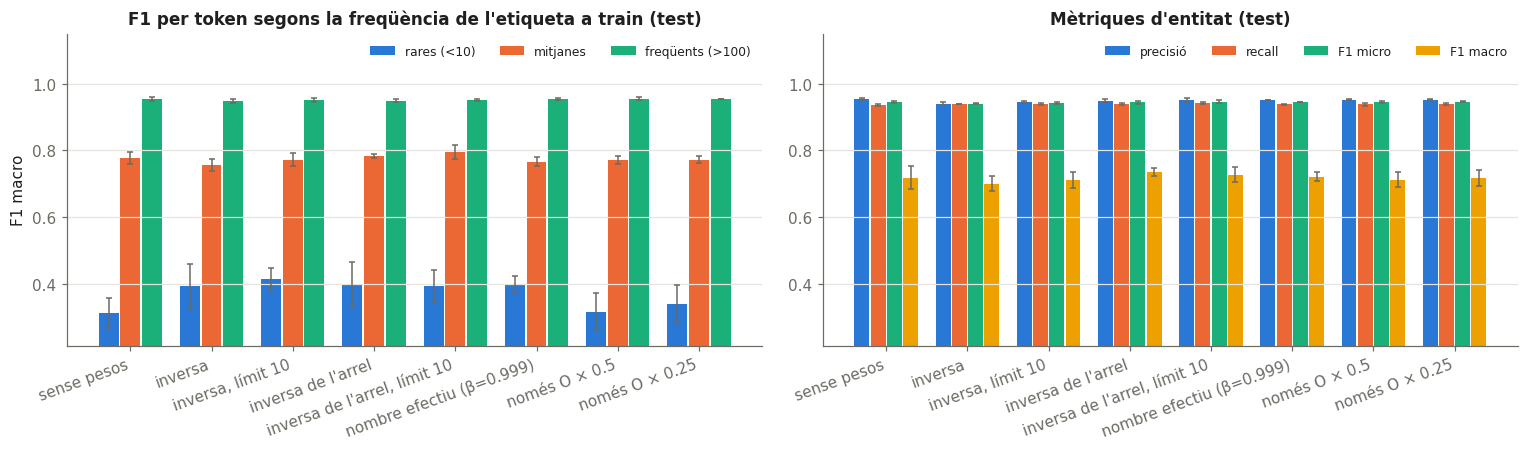

In [13]:
display(ex7_6.weights_table().round(3))
r76 = run(ex7_6.configs())
s76, fig76 = ex7_6.report(r76, save_as=fig_name("ex7_6_balanceig"))
display(s76.round(4))

**Anàlisi dels resultats.** Els pesos de classe fan el que preveu la hipòtesi, però no en la mètrica que fem
servir per decidir. La F1 per token del grup de classes rares (menys de 10 exemples a train) passa de 0,31 a
0,39-0,41 amb qualsevol esquema basat en la freqüència, i la F1 macro per token puja entre 1 i 3 punts, a canvi
d'una mica de precisió (de 0,954 a 0,940-0,951). La F1 micro d'entitats, en canvi, no millora en cap cas, i la
inversa pura l'empitjora mig punt: amb pesos de fins a 260 vegades el del token mitjà, el model necessita 36
èpoques per convergir i sacrifica les classes freqüents, que són la gran majoria de les entitats. Els esquemes
suaus són el millor compromís, també com esperàvem: la inversa de l'arrel amb límit 10 manté la F1 micro (0,9458
a test) i guanya 3 punts de F1 macro per token. Reduir només el pes de `O` no té cap efecte visible.

Com que el model final es tria per F1 micro de validació, els pesos no hi entren. Si l'objectiu del sistema fos
detectar millor les entitats poc freqüents, la inversa de l'arrel amb límit seria la tria natural: la mètrica
d'avaluació forma part del disseny, no és un detall final.

### Experiments addicionals: CRF, esquema d'etiquetes i vocabulari

Disseny 2×2 entre esquema (BIO, BILOU) i decodificador (softmax, CRF implementat a mà amb forward i Viterbi), i
`min_freq = 1`. Hipòtesi: amb softmax, BILOU produeix més seqüències impossibles que BIO, i el CRF, que aprèn
quines transicions són vàlides, les redueix gairebé a zero.

15 execucions, 3 ja a la cache, 12 per entrenar
[1/12] BILOU + CRF (seed 0): val F1 0.9710, 18 èpoques, 2.8 min
[2/12] BILOU + CRF (seed 1): val F1 0.9771, 20 èpoques, 3.1 min
[3/12] BIO + softmax (seed 0): val F1 0.9721, 21 èpoques, 4.0 min
[4/12] BIO + softmax (seed 1): val F1 0.9741, 20 èpoques, 4.8 min
[5/12] BIO + softmax (seed 2): val F1 0.9759, 21 èpoques, 5.6 min
[6/12] BILOU + CRF (seed 2): val F1 0.9744, 21 èpoques, 5.9 min
[7/12] BIO + CRF (seed 1): val F1 0.9746, 14 èpoques, 8.0 min
[8/12] BIO + CRF (seed 0): val F1 0.9727, 19 èpoques, 8.5 min
[9/12] min_freq = 1 (seed 0): val F1 0.9740, 18 èpoques, 9.2 min
[10/12] min_freq = 1 (seed 1): val F1 0.9760, 23 èpoques, 10.1 min
[11/12] min_freq = 1 (seed 2): val F1 0.9718, 20 èpoques, 11.0 min
[12/12] BIO + CRF (seed 2): val F1 0.9751, 20 èpoques, 11.0 min


,family,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds,invàlides val (de 900),invàlides test (de 893)
name,,,,,,,,,,,,,,,
BILOU + softmax (baseline),Referència,0.9737,0.0028,0.9450,0.0037,0.7173,0.0345,0.6824,0.0157,385587.0,12.6667,1.8963,3,22.3333,43.6667
BILOU + CRF,Decodificador,0.9742,0.0031,0.9462,0.0026,0.7291,0.0255,0.6899,0.0086,417986.0,14.6667,7.7547,3,13.6667,26.3333
BIO + softmax,Esquema,0.9740,0.0019,0.9446,0.0022,0.7271,0.0302,0.7502,0.0258,370424.0,15.6667,2.0303,3,9.6667,23.0000
BIO + CRF,Esquema,0.9741,0.0013,0.9460,0.0017,0.7373,0.0218,0.7400,0.0368,385064.0,12.6667,7.7993,3,7.0000,15.0000
min_freq = 1,Vocabulari,0.9739,0.0021,0.9475,0.0016,0.7212,0.0089,0.6814,0.0194,416691.0,15.3333,1.9983,3,22.3333,40.6667


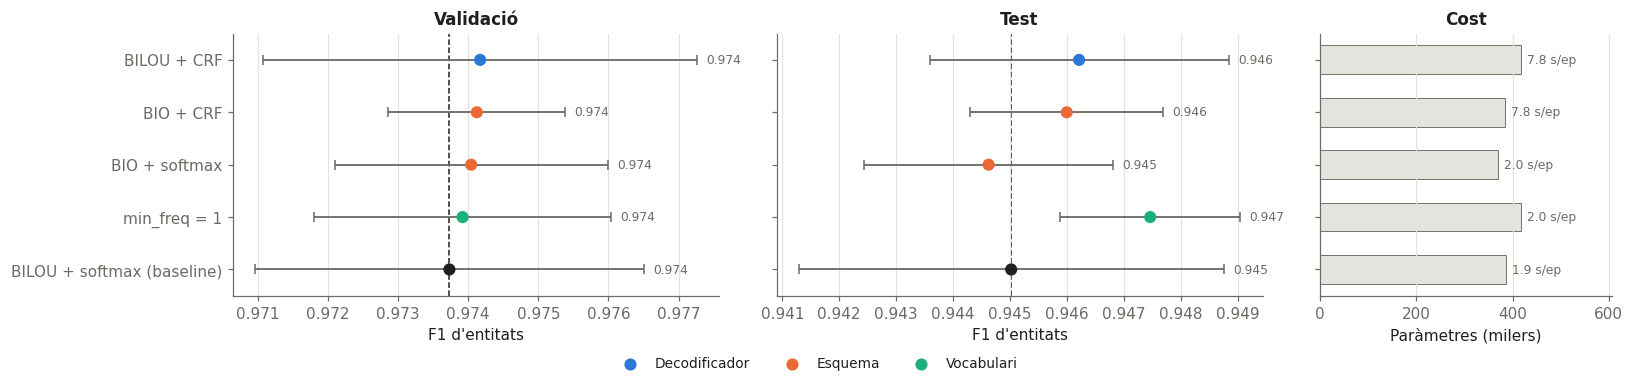

In [14]:
rx = run(extras.configs())
sx, figx = extras.report(rx, save_as=fig_name("extra_crf_esquema"))
display(sx.round(4))

**Anàlisi dels resultats.** El CRF redueix les seqüències impossibles, però no les elimina: amb BILOU passen de 44
a 26 oracions de test (−40%) i amb BIO de 23 a 15. La hipòtesi que les reduiria gairebé a zero no es compleix
perquè el CRF aprèn les transicions a partir de les dades, sense cap restricció explícita. Les transicions entre
etiquetes poc freqüents queden mal estimades i, en una oració amb una entitat rara, les emissions encara poden
guanyar a la transició. Imposar una puntuació de −∞ a les transicions prohibides (decodificació restringida) les
eliminaria del tot. En F1 micro el CRF gairebé no canvia res (+0,1 punts a test), però puja la F1 macro d'entitats
(+1,2 punts amb BILOU, +1,0 amb BIO), coherent amb el fet que corregeix sobretot els límits d'entitats rares i
llargues. El cost és alt: quatre vegades més temps per època, pels algorismes forward i Viterbi, que són
seqüencials.

BIO i BILOU donen la mateixa F1 d'entitats (0,9740 i 0,9737 de validació). Amb softmax, BILOU produeix el doble de
seqüències invàlides que BIO (44 enfront de 23), perquè té més maneres d'equivocar-se, i el senyal extra sobre els
límits no compensa tenir 178 classes en lloc de 119. La F1 macro per token no és comparable entre esquemes,
perquè el conjunt de classes és diferent. Finalment, `min_freq = 1` tampoc no canvia res (0,9739): mapar a
`<unk>` les paraules amb un sol exemple no fa perdre informació útil.

### Model final, ablació i significança

El model final es construeix automàticament amb els resultats de validació: de cada apartat s'agafa la
configuració guanyadora i només s'hi afegeix si millora la seva referència per més d'una desviació estàndard.
Després, l'ablació treu un component cada vegada (5 llavors) i un bootstrap pareat sobre les oracions de test
diu si la millora respecte al baseline és significativa.

embedding (7.1): s'afegeix 'glove-300 congelat' (guany de validació +0.0058)
char-CNN (7.2): s'afegeix 'char-CNN 50/50 k3 + BiLSTM' (guany de validació +0.0040)
encoder (7.2-7.4): no millora més enllà del soroll (guany de validació +0.0027)
dropout: es fa servir el model de 7.5 'BiLSTM 1×128'
dropout (7.5): s'afegeix 'BiLSTM 1×128 + tot 0.3' (guany de validació +0.0032)
pesos de classe (7.6): no millora més enllà del soroll (guany de validació +0.0002)
esquema i decodificador (extra): no millora més enllà del soroll (guany de validació +0.0004)

Model final: {'data': {'scheme': 'BILOU', 'min_freq': 2, 'val_size': 900}, 'model': {'embedding_dim': 300, 'pretrained': 'glove-300', 'freeze_embeddings': True, 'embedding_dropout': 0.3, 'char_encoder': {'kind': 'char_cnn', 'params': {'char_dim': 50, 'filters': 50, 'kernel_size': 3}}, 'blocks': [{'kind': 'rnn', 'params': {'rnn_type': 'lstm', 'hidden_dim': 128, 'num_layers': 1, 'bidirectional': True}}], 'classifier_dropout': 0.3, 'decoder': 'sof

,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds
name,,,,,,,,,,,,
baseline,0.9738,0.0021,0.9463,0.0035,0.7273,0.0280,0.6937,0.0198,385587.0,12.6,1.9156,5
model final,0.9789,0.0016,0.9552,0.0021,0.7771,0.0054,0.7441,0.0142,547073.0,16.8,2.2285,5
final − embedding,0.9792,0.0017,0.9539,0.0012,0.7634,0.0061,0.7349,0.0192,446337.0,20.0,2.2117,5
final − char-CNN,0.9778,0.0012,0.9527,0.0018,0.7710,0.0046,0.7226,0.0206,486323.0,15.0,1.8209,5
final − dropout,0.9783,0.0018,0.9544,0.0056,0.7782,0.0127,0.7454,0.0195,547073.0,13.4,2.0552,5


,delta,ci_low,ci_high,p_value
0,0.0076,0.0017,0.0134,0.006
1,0.0136,0.0079,0.0199,0.000
2,0.0053,-0.0001,0.0109,0.026
3,0.0113,0.0057,0.0170,0.000
4,0.0066,0.0018,0.0115,0.005


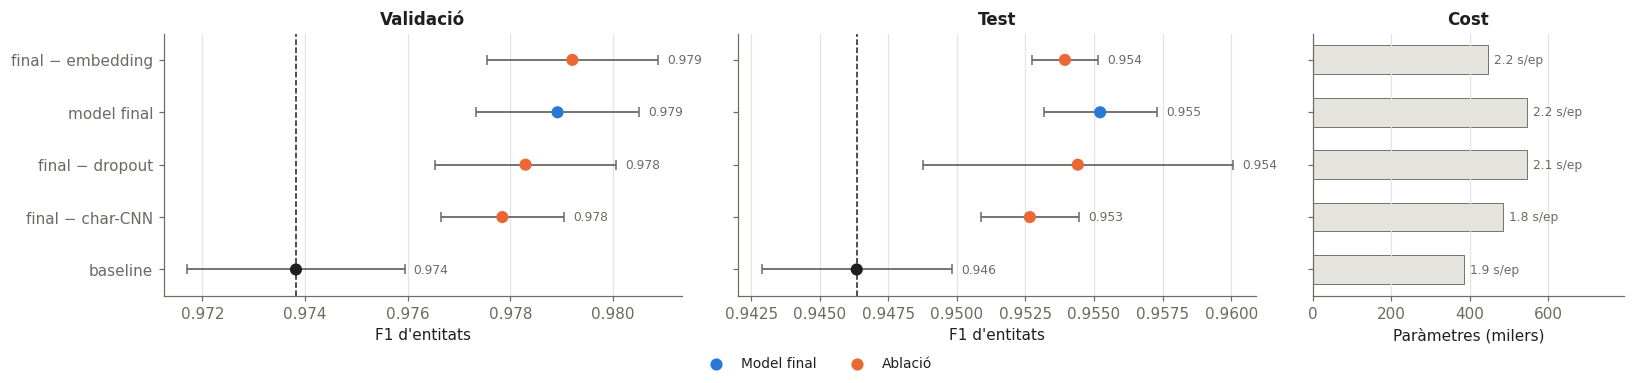

In [15]:
section_results = {"7.1": r71, "7.2": r72, "7.3": r73, "7.4": r74, "7.5": r75, "7.6": r76, "extra": rx}
components, log = final.build_final(section_results)
print("\n".join(log))
final_cfg = final.compose(components)
print("\nModel final:", {k: v for k, v in final_cfg.to_dict().items() if k in ("data", "model")})
print("Entrenament:", final_cfg.to_dict()["train"])

rf = run(final.ablation_configs(components), seeds=FINAL_SEEDS)
sf, figf = final.report(rf, save_as=fig_name("final_ablacio"))
display(sf.round(4))
display(final.significance(rf).round(4))

,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,n_params
name,,,,
7.1: glove-300 congelat,0.9521,0.0003,0.7730,486323.0
7.2: char-CNN 50/50 k3 + BiLSTM,0.9512,0.0035,0.7552,446337.0
7.3: BiLSTM 2×256,0.9508,0.0023,0.7462,2534707.0
7.4: BiLSTM (baseline),0.9450,0.0037,0.7173,385587.0
7.5: BiLSTM 1×128 + tot 0.3,0.9506,0.0026,0.7460,385587.0
7.6: només O × 0.25,0.9458,0.0017,0.7177,385587.0
extra: BILOU + CRF,0.9462,0.0026,0.7291,417986.0
baseline,0.9463,0.0035,0.7273,385587.0
model final,0.9552,0.0021,0.7771,547073.0


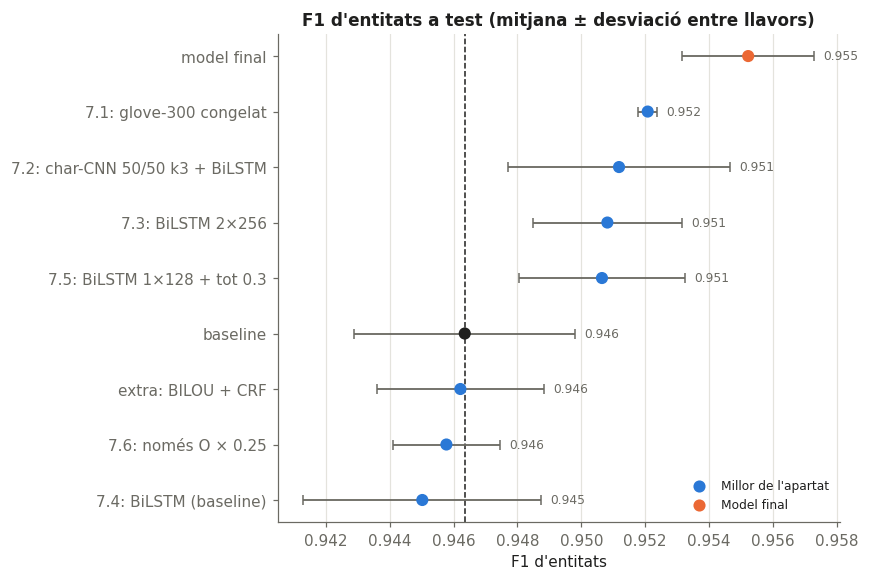

In [16]:
s_all, fig_all = final.overview_figure(section_results, rf, save_as=fig_name("resum_global"))
display(s_all[["test_entity_f1_mean", "test_entity_f1_std", "test_entity_f1_macro_mean", "n_params"]].round(4))

**Anàlisi dels resultats.** El model final combina els tres components que han superat el llindar de soroll:
GloVe de 300 dimensions congelat, la char-CNN 50/50 i dropout 0,3 a l'embedding i abans del classificador, tot
sobre la mateixa BiLSTM d'una capa i 128 unitats del baseline. L'encoder, els pesos de classe i el CRF queden fora,
perquè els seus guanys de validació (+0,27, +0,02 i +0,04 punts) no superen la desviació entre llavors. Amb 5
llavors, el model final arriba a 0,9789 ± 0,0016 de validació i 0,9552 ± 0,0021 de test, enfront de 0,9738 i
0,9463 del baseline, i la F1 macro d'entitats puja de 0,727 a 0,777. El bootstrap pareat dona una millora
significativa a les cinc llavors (p ≤ 0,026), amb guanys d'entre 0,5 i 1,4 punts.

L'ablació mostra que els components se solapen. Treure la char-CNN és el que més costa (−0,25 punts de test i −2,2
de F1 macro per token). Treure GloVe gairebé no afecta la validació (fins i tot puja, 0,9792), però costa 0,13
punts de test i 1,4 de F1 macro. Treure el dropout queda dins del soroll. Les tres peces ataquen el mateix
problema, les paraules rares o no vistes, des de punts diferents (vectors externs, ortografia i regularització),
i per això juntes aporten menys que la suma de les parts. La millora més gran de tot l'exercici no ve de
l'arquitectura, on cap encoder ha superat clarament la BiLSTM simple, sinó de la representació d'entrada.

Cal remarcar una limitació. L'early stopping amb `min_delta = 0,001` atura el baseline cap a l'època 13, mentre que
a l'Exercici 6, sense `min_delta` i amb 30 èpoques, la F1 encara pujava lentament fins a 0,953 de test. Totes les
configuracions de l'Exercici 7 comparteixen aquest criteri, així que les comparacions són justes, però els valors
absoluts són una mica més baixos i part del guany del model final podria venir de convergir més a poc a poc
(millor època 16,8 enfront de 12,6). La cel·la següent ho comprova.

### Control: entrenament sense `min_delta`

Per comprovar si el guany del model final depèn del criteri d'aturada, es reentrenen el baseline i el model final
sense `min_delta`, amb paciència 10 i fins a 60 èpoques (5 llavors). Si la millora vingués només de convergir més a
poc a poc, en deixar entrenar tots dos models fins al final desapareixeria.

In [18]:
from ner import summarize

rr = run(final.robustness_configs(components), seeds=FINAL_SEEDS)
display(summarize(rr).round(4))
display(final.significance(rr, final.BASELINE_LONG, final.FINAL_LONG).round(4))

AttributeError: module 'ner.experiments.final' has no attribute 'robustness_configs'

**Anàlisi dels resultats:** *pendent d'executar les graelles a Colab.*

10 execucions, 0 ja a la cache, 10 per entrenar
[1/10] baseline (sense min_delta) (seed 0): val F1 0.9728, 36 èpoques, 1.5 min
[2/10] baseline (sense min_delta) (seed 1): val F1 0.9793, 60 èpoques, 2.5 min
[3/10] baseline (sense min_delta) (seed 2): val F1 0.9759, 41 èpoques, 3.2 min
[4/10] baseline (sense min_delta) (seed 3): val F1 0.9742, 27 èpoques, 3.5 min
[5/10] model final (sense min_delta) (seed 0): val F1 0.9822, 37 èpoques, 5.1 min
[6/10] baseline (sense min_delta) (seed 4): val F1 0.9778, 60 èpoques, 5.4 min
[7/10] model final (sense min_delta) (seed 2): val F1 0.9782, 31 èpoques, 6.7 min
[8/10] model final (sense min_delta) (seed 1): val F1 0.9826, 47 èpoques, 7.1 min
[9/10] model final (sense min_delta) (seed 3): val F1 0.9817, 41 èpoques, 8.5 min
[10/10] model final (sense min_delta) (seed 4): val F1 0.9831, 46 èpoques, 8.8 min


,val_entity_f1_mean,val_entity_f1_std,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,test_entity_f1_macro_std,test_token_f1_macro_mean,test_token_f1_macro_std,n_params,best_epoch,sec_per_epoch,n_seeds
name,,,,,,,,,,,,
baseline (sense min_delta),0.9760,0.0026,0.9498,0.0035,0.7362,0.0249,0.7177,0.0191,385587.0,35.0,1.9503,5
model final (sense min_delta),0.9816,0.0020,0.9568,0.0015,0.7905,0.0115,0.7721,0.0080,547073.0,30.4,2.1122,5


,delta,ci_low,ci_high,p_value
0,0.0067,0.0010,0.0125,0.014
1,0.0106,0.0058,0.0156,0.000
2,0.0097,0.0050,0.0153,0.000
3,0.0036,-0.0020,0.0090,0.100
4,0.0043,-0.0004,0.0089,0.035


,test_entity_f1_mean,test_entity_f1_std,test_entity_f1_macro_mean,n_params
name,,,,
7.1: glove-300 congelat,0.9521,0.0003,0.7730,486323.0
7.2: char-CNN 50/50 k3 + BiLSTM,0.9512,0.0035,0.7552,446337.0
7.3: BiLSTM 2×256,0.9508,0.0023,0.7462,2534707.0
7.4: BiLSTM + atenció 1 capa,0.9352,0.0036,0.6706,913203.0
7.5: BiLSTM 1×128 + tot 0.3,0.9506,0.0026,0.7460,385587.0
7.6: només O × 0.25,0.9458,0.0017,0.7177,385587.0
extra: BILOU + CRF,0.9462,0.0026,0.7291,417986.0
baseline,0.9463,0.0035,0.7273,385587.0
model final,0.9552,0.0021,0.7771,547073.0


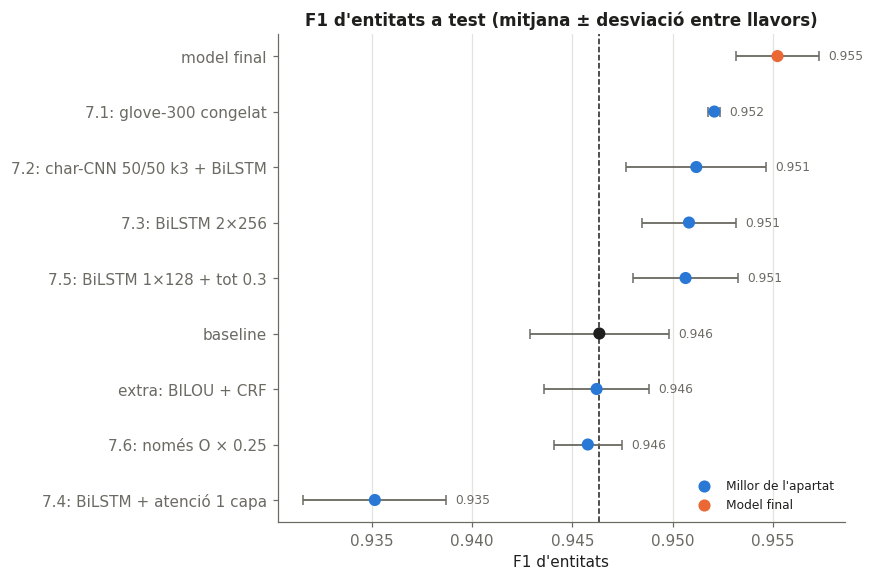

In [19]:
import importlib
from ner import summarize
importlib.reload(final)   # carga la versión nueva de final.py

# Control sin min_delta (lo único que entrena, unos 15-20 min)
rr = run(final.robustness_configs(components), seeds=FINAL_SEEDS)
display(summarize(rr).round(4))
display(final.significance(rr, final.BASELINE_LONG, final.FINAL_LONG).round(4))

# Figura resumen corregida (no entrena nada)
s_all, fig_all = final.overview_figure(section_results, rf, save_as=fig_name("resum_global"))
display(s_all[["test_entity_f1_mean", "test_entity_f1_std", "test_entity_f1_macro_mean", "n_params"]].round(4))

### Anàlisi d'errors

Es fa servir l'execució amb F1 de validació mediana de cada model, per no triar la llavor més afortunada. Cada
error d'entitat es classifica com a tipus equivocat, límits equivocats, no detectada o inventada.

In [17]:
from ner import analysis
from ner.config import ExperimentConfig
from ner.data import prepare_data
from ner.metrics import entity_report

categories = {}
for name in (final.BASELINE, final.FINAL):
    run_result = analysis.median_seed_result(rf, name)
    cfg = ExperimentConfig.from_dict(run_result["config"])
    test = prepare_data(cfg.data).splits["test"]
    pred = [p.split() for p in run_result["test_pred"]]
    cat, conf = analysis.error_summary(test.gold, pred)
    categories[name] = cat
    print(f"\n=== {name}: confusions de tipus més freqüents ===")
    display(conf)
display(pd.DataFrame(categories).round(3))

report_final = entity_report(test.gold, pred, cfg.data.scheme)
print("Entitats amb pitjor F1 al model final (amb suport mínim de 5):")
display(report_final[report_final["support"] >= 5].head(10).round(3))
for example in analysis.error_examples(test.sentences, test.gold, pred, n=4):
    print(example, end="\n\n")


=== baseline: confusions de tipus més freqüents ===


,real,predit,vegades
0,city_name,toloc.city_name,16
1,depart_time.period_of_day,depart_time.time,13
2,airport_name,fromloc.airport_name,10
3,toloc.state_name,toloc.city_name,4
4,city_name,fromloc.city_name,4
5,airline_code,airport_code,4
6,depart_date.day_name,arrive_date.day_name,3
7,city_name,fromloc.airport_name,3
8,state_name,toloc.state_name,3
9,depart_date.year,depart_date.day_number,3



=== model final: confusions de tipus més freqüents ===


,real,predit,vegades
0,city_name,toloc.city_name,18
1,depart_time.period_of_day,depart_time.time,10
2,airport_name,fromloc.airport_name,9
3,state_name,toloc.state_name,7
4,aircraft_code,flight_number,6
5,city_name,fromloc.city_name,4
6,toloc.city_name,fromloc.city_name,3
7,airport_code,fromloc.airport_code,3
8,depart_date.month_name,arrive_date.month_name,2
9,depart_date.day_name,arrive_date.day_name,2


,baseline,model final
inventada,0.195,0.157
límits equivocats,0.124,0.138
no detectada,0.162,0.075
tipus equivocat,0.519,0.629


Entitats amb pitjor F1 al model final (amb suport mínim de 5):


,precision,recall,f1-score,support
state_name,0.000,0.000,0.000,9.0
airport_code,0.600,0.333,0.429,9.0
airport_name,0.818,0.429,0.562,21.0
city_name,0.939,0.544,0.689,57.0
flight_number,0.556,0.909,0.690,11.0
fromloc.airport_name,0.545,1.000,0.706,12.0
flight_mod,0.783,0.750,0.766,24.0
arrive_date.day_number,0.714,0.833,0.769,6.0
arrive_date.month_name,0.714,0.833,0.769,6.0
fromloc.airport_code,0.625,1.000,0.769,5.0


paraula        real                             predit
list           O                                O
california     U-state_name                     U-toloc.state_name  ✗
airports       O                                O

paraula        real                             predit
list           O                                O
california     U-state_name                     U-toloc.state_name  ✗
nevada         U-state_name                     U-toloc.state_name  ✗
arizona        U-state_name                     U-toloc.state_name  ✗
airports       O                                O

paraula        real                             predit
get            O                                O
flights        O                                O
from           O                                O
milwaukee      U-fromloc.city_name              U-fromloc.city_name
to             O                                O
dtw            U-toloc.airport_code             U-toloc.city_name  ✗

paraula        

**Anàlisi dels resultats.** Dins dels errors del model final, les entitats no detectades passen del 16% al 7,5%,
mentre que la gran majoria del que queda (63%) són errors de tipus: el model troba el tram correcte però li
assigna un rol equivocat. Les confusions més freqüents són les mateixes en els dos models: `city_name` predit com
a `toloc.city_name`, `period_of_day` com a `time` i `airport_name` com a `fromloc.airport_name`. Els exemples en
mostren l'origen. A ATIS, `city_name` i `state_name` sense rol s'anoten en preguntes que no tracten d'un trajecte
("list california airports", "which airport is closest to ontario california"), mentre que la gran majoria de
ciutats del corpus són origen o destinació. El model aprèn que una ciutat gairebé sempre té rol i no té prou
context per detectar quan la pregunta no és sobre un vol; per això `state_name` té F1 0 i `city_name` un recall de
només 0,54. Aquests errors depenen de la intenció de la frase més que de les paraules, i suggereixen que un model
conjunt que aprengués la intenció (Part 1) i les entitats alhora podria resoldre bona part d'aquests casos.

---

<h1><a name="section-four"> 4. Lliurable </a></h1>

Heu d'entregar un document PDF de com a **màxim 10 pàgines** que incloga els resultats de tots els exercicis així com una explicació de cadascun dels resultats i de la modificació que heu fet. L'estructura del document és:

1. Introducció.
2. Experiments i Resultats (amb raonament).
3. Conclusions.

No cal que afegiu el vostre codi al document, podeu entregar el *notebook* juntament amb el document.

 ---